# HỆ THỐNG HỖ TRỢ QUẢN LÝ VÀ PHÂN CÔNG GIẢNG DẠY ĐẠI HỌC (UCTP)

Thuật toán Lai 3 Giai đoạn (3-Stage Hybrid Matheuristic) cho bài toán phân công giảng viên, xếp kíp giờ và phân phòng học, dựa trên bộ dữ liệu chuẩn quốc tế ITC 2019.

---

### Mục lục

1. Cấu hình chung (Config)
2. Import thư viện (Cell 1)
3. Giới thiệu dự án
4. Mô tả dữ liệu ban đầu và câu hỏi nghiên cứu
5. XML Parser và làm sạch dữ liệu (Cell 2)
6. EDA — biểu đồ thống kê tổng quan hạ tầng và quy mô (Cell 3)
7. Biến Teacher — mô tả, lý do bổ sung, ý nghĩa
8. Sinh dữ liệu Teacher và tính toán Stage 0: Deg(i), Bottleneck(c), phân nhóm (Cell 4)
9. Biểu đồ Stage 0 — bar chart, pie chart, network graph (Cell 5)
10. Stage 1 — Priority-Based CP-SAT Solver (Cell 6)
11. Stage 2 — Adaptive Iterated Local Search with Great Deluge (Cell 7)
12. Biểu đồ hội tụ thuật toán và heatmap phân bổ kíp giờ (Cell 8)
13. Bảng tổng hợp chỉ số hiệu năng và xuất file kết quả (Cell 9)

## 1. Cấu hình chung (Config)

Cell dưới đây là cấu hình chung của toàn bộ notebook — chạy 1 lần duy nhất, các cell sau đều tham chiếu tới các biến ở đây.

In [3]:
from pathlib import Path

# Duong dan goc cua du an - sua neu can dung duong dan tuyet doi
PROJECT_ROOT = Path('.').resolve()
DATA_DIR = PROJECT_ROOT / 'data' / 'raw_itc2019'
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Seed dam bao tai lap ket qua
RANDOM_SEED = 42

# Tham so sinh du lieu Teacher (dung o muc 3 / Cell 4b)
TEACHER_GEN_CONFIG = {
    'teachers_per_subpart': 2,
    'pool_ratio': 0.6,
    'zipf_a': 1.0,
}

# Nguong phan loai 3 nhom giao vien theo Deg(i) (Stage 0)
STAGE0_THRESHOLDS = {
    'group1_max_deg': 1,   # Deg(i) <= 1 -> Nhom 1 (don nang)
    'group2_max_deg': 3,   # 2 <= Deg(i) <= 3 -> Nhom 2 (trung binh); con lai -> Nhom 3 (da nang)
}

# Trong so ham muc tieu Stage 2 (rang buoc mem phan cong giao vien)
STAGE2_WEIGHTS = {
    'w_teacher_preference': 1.0,
    'w_schedule_gap': 1.0,
    'w_student_conflict': 1.0,
}

# Tham so thuat toan AILS + Great Deluge o Stage 2
STAGE2_CONFIG = {
    'max_iterations': 20000,
    'great_deluge_initial_level_factor': 1.2,
    'great_deluge_decay_rate': 0.9998,
}

# Mau sac dung thong nhat cho moi bieu do 3 nhom giao vien
PLOT_COLORS = {
    'group1': '#d9534f',
    'group2': '#f0ad4e',
    'group3': '#5cb85c',
}

print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATA_DIR:', DATA_DIR)
print('RANDOM_SEED:', RANDOM_SEED)

PROJECT_ROOT: D:\uctp_project
DATA_DIR: D:\uctp_project\data\raw_itc2019
RANDOM_SEED: 42


### Import thư viện

In [4]:
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from collections import defaultdict, Counter
from datetime import datetime
import random

# ortools can cai rieng: pip install ortools
from ortools.sat.python import cp_model

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
sns.set_theme(style='whitegrid')

print('Da import thanh cong tat ca thu vien can thiet.')


Da import thanh cong tat ca thu vien can thiet.


## 3. Giới thiệu dự án

**Bài toán**: Xếp lịch giảng dạy đại học (University Course Timetabling) là bài toán tối ưu tổ hợp NP-hard, đòi hỏi gán đồng thời thời gian, phòng học, và (trong phạm vi đề tài này) giảng viên cho từng lớp học phần, sao cho thỏa mãn toàn bộ ràng buộc cứng và tối thiểu hóa tổng phạt của các ràng buộc mềm.

**Nền tảng dữ liệu**: Đề tài sử dụng bộ dữ liệu chuẩn quốc tế ITC 2019 (International Timetabling Competition 2019) — bộ dữ liệu thực tế lớn nhất hiện có cho bài toán này, thu thập từ khoảng 10 cơ sở giáo dục trên nhiều châu lục thông qua hệ thống UniTime, với quy mô lớn nhất lên tới gần 9.000 lớp và hơn 38.000 sinh viên trong một instance.

**Khoảng trống nghiên cứu**: Bài toán gốc của ITC 2019 chỉ giải quyết việc gán thời gian và phòng học kết hợp xếp nhóm sinh viên, hoàn toàn không có khái niệm phân công giảng viên (trình bày chi tiết ở Mục 4). Đề tài mở rộng bài toán gốc bằng cách bổ sung bài toán con Phân công giảng viên (Faculty Teaching Assignment) trên cùng nền benchmark này, và đề xuất Thuật toán Lai 3 Giai đoạn để giải bài toán mở rộng đó.

**Mục tiêu và đóng góp**:

1. Xây dựng thuật toán 3 giai đoạn giải đồng thời phân công giảng viên, thời gian và phòng học.
2. Đánh giá so sánh tầng lõi (Room + Time) với kết quả các thuật toán top thế giới trên cùng instance ITC 2019.
3. Xây dựng baseline định lượng đầu tiên cho tầng mở rộng (Faculty Assignment).
4. Phát triển thành ứng dụng web hỗ trợ quản lý và phân công giảng dạy thực tế cho một khoa hoặc trường.


## 4. Mô tả dữ liệu ban đầu

### 4.1. Số lượng file

Bộ dữ liệu ITC 2019 gồm 30 file `.xml`, chia làm 3 đợt công bố, mỗi đợt 10 instance thực tế (early, middle, late), lấy từ dữ liệu thật của các trường đại học khác nhau. Quy mô rất khác biệt giữa các file, từ vài trăm đến hàng nghìn lớp học.

Hai file mẫu đã được tải và kiểm tra thực tế để đối chiếu cấu trúc dữ liệu: `wbg-fal10.xml`, `pu-cs-fal07.xml`.

### 4.2. Cấu trúc và ý nghĩa các trường dữ liệu

**a) Root `<problem>` — một dòng cấu hình mỗi file**

| Cột | Kiểu | Ý nghĩa |
|---|---|---|
| name | string | Tên định danh instance (ví dụ: wbg-fal10) |
| nrDays | int | Số ngày mỗi tuần (thường bằng 7) |
| nrWeeks | int | Số tuần trong học kỳ (13 đến 16) |
| slotsPerDay | int | Số khung giờ mỗi ngày (thường 288, mỗi slot 5 phút) |
| optimization.time / room / distribution / student | int | Trọng số cho 4 thành phần hàm mục tiêu gốc, bắt buộc giữ nguyên để so sánh sau này |

**b) `<rooms>`**

| Cột | Ý nghĩa |
|---|---|
| id | Mã phòng |
| capacity | Sức chứa |
| unavailable (days, start, length, weeks) | Khung giờ phòng không khả dụng |

**c) `<course><config><subpart><class>` — cấu trúc phân cấp 4 tầng**

| Tầng | Ý nghĩa |
|---|---|
| course | Học phần |
| config | Một cấu hình học hợp lệ của học phần, sinh viên chọn một config |
| subpart | Một loại buổi học trong config (Lecture, Lab, Seminar...) |
| class | Lớp học cụ thể, đơn vị nhỏ nhất cần xếp lịch |

Trong class: `id`, `limit` (sĩ số tối đa) là thuộc tính; phần tử con gồm:

- `room (id, penalty)`: danh sách phòng khả dĩ kèm điểm phạt nếu chọn
- `time (days, start, length, weeks, penalty)`: danh sách khung giờ khả dĩ kèm điểm phạt

**d) `<distribution>` — ràng buộc phân bổ giữa hai lớp trở lên**

| Cột | Ý nghĩa |
|---|---|
| type | Loại ràng buộc (19 loại: NotOverlap, SameRoom, SameAttendees, Precedence, MinGap...) |
| required hoặc penalty | required="true" là ràng buộc cứng; có penalty là ràng buộc mềm |
| class (id) | Danh sách lớp chịu ràng buộc |

**e) `<student>`**

| Cột | Ý nghĩa |
|---|---|
| id | Mã sinh viên |
| course (id) | Danh sách học phần sinh viên đã đăng ký |

### 4.3 Câu hỏi nghiên cứu

**RQ1**: Đặc điểm cấu trúc dữ liệu ITC 2019 (quy mô lớp học, mật độ ràng buộc phân bổ, tỷ lệ phòng/thời gian khả dĩ trên mỗi lớp) khác biệt như thế nào giữa các instance, và điều này ảnh hưởng ra sao đến độ khó của bài toán gốc?
— Trả lời bằng: biểu đồ EDA ở Cell 3.

**RQ2**: Sau khi bổ sung biến Teacher, mức độ khan hiếm giảng viên (Deg(i)) và độ cổ chai của lớp học (Bottleneck(c)) phân bố như thế nào trong bộ dữ liệu, và tỷ lệ giữa 3 nhóm giảng viên (đơn năng, trung bình, đa năng) là bao nhiêu?
— Trả lời bằng: biểu đồ Stage 0 (bar chart phân nhóm, pie chart tỷ lệ, network graph liên kết giảng viên–lớp) ở Cell 5.

**RQ3**: Chiến lược giải tuần tự theo mức độ ưu tiên (Sequential Fixing: nhóm đơn năng trước, đa năng sau) tại Stage 1 có giúp đạt nghiệm khả thi (Hard_Penalty = 0) nhanh hơn và ổn định hơn so với việc giải không phân loại ưu tiên hay không?
— Trả lời bằng: bảng so sánh thời gian giải và tỷ lệ khả thi giữa hai chiến lược, thực hiện ở Cell 6.

**RQ4**: Thuật toán Adaptive Iterated Local Search kết hợp Great Deluge tại Stage 2 hội tụ với tốc độ như thế nào theo số vòng lặp, và các toán tử láng giềng (Preference-Swap, Lecturer-Reassign, Room-Move) đóng góp khác nhau ra sao vào việc giảm Soft_Penalty?
— Trả lời bằng: đường cong hội tụ (Convergence Curve) và heatmap phân bổ kíp giờ ở Cell 8.

**RQ5**: Kết quả tầng lõi (Room + Time + Student, theo đúng trọng số optimization gốc của ITC 2019) do thuật toán đề xuất tạo ra so với kết quả tốt nhất đã công bố của các thuật toán khác trên cùng instance chênh lệch bao nhiêu phần trăm?
— Trả lời bằng: bảng so sánh benchmark ở Cell 9, đối chiếu với kết quả công bố trên itc2019.org.

**RQ6**: Việc bổ sung ràng buộc phân công giảng viên làm thay đổi thời gian giải và chất lượng nghiệm tổng thể (so với khi chỉ giải Room + Time thuần) ở mức độ nào, và mức độ khan hiếm giảng viên tác động ra sao đến độ khó của bài toán mở rộng?
— Trả lời bằng: bảng chỉ số hiệu năng (Metrics Summary Table) ở Cell 9, so sánh phiên bản có và không có ràng buộc Teacher.

## 5. XML Parser và làm sạch dữ liệu (Cell 2)
1. Kiểm tra tham chiếu treo: class.room.id hoặc distribution.class.id trỏ tới id không tồn tại, cần validate trước khi build đồ thị.
2. Loại bỏ class có limit bằng 0 hoặc không có bất kỳ time khả dĩ nào (infeasible-by-design), cần loại hoặc gắn cờ riêng.
3. Chuẩn hóa bitmask days và weeks (chuỗi dạng "1010100") thành danh sách boolean hoặc tập chỉ số, để tính toán chồng lấn nhanh hơn thay vì so sánh chuỗi.
4. Kiểm tra config không có subpart nào hoặc subpart không có class nào, loại khỏi cấu trúc chọn config của sinh viên.
5. Encoding: một số file có BOM ở đầu file, cần dùng encoding='utf-8-sig' khi đọc để tránh lỗi parse.

In [5]:
def parse_itc_instance(xml_path):
    """Doc file XML ITC 2019, tra ve du lieu day du: 3 DataFrame + 2 dict chi tiet gio/phong."""
    tree = ET.parse(xml_path)
    root = tree.getroot()

    rooms = []
    for r in root.find('rooms'):
        rooms.append({'room_id': r.get('id'), 'capacity': int(r.get('capacity'))})
    df_rooms = pd.DataFrame(rooms)

    classes = []
    class_times = {}   # class_id -> list [{'days','start','length','weeks','penalty'}]
    class_rooms = {}   # class_id -> list [{'room_id','penalty'}]

    for course in root.find('courses'):
        course_id = course.get('id')
        for config in course.findall('config'):
            config_id = config.get('id')
            for subpart in config.findall('subpart'):
                subpart_id = subpart.get('id')
                for cls in subpart.findall('class'):
                    class_id = cls.get('id')
                    time_opts = [{
                        'days': t.get('days'), 'start': int(t.get('start')),
                        'length': int(t.get('length')), 'weeks': t.get('weeks'),
                        'penalty': int(t.get('penalty', 0)),
                    } for t in cls.findall('time')]
                    room_opts = [{
                        'room_id': rm.get('id'), 'penalty': int(rm.get('penalty', 0)),
                    } for rm in cls.findall('room')]

                    class_times[class_id] = time_opts
                    class_rooms[class_id] = room_opts

                    classes.append({
                        'class_id': class_id, 'course_id': course_id,
                        'config_id': config_id, 'subpart_id': subpart_id,
                        'limit': int(cls.get('limit')),
                        'n_possible_rooms': len(room_opts),
                        'possible_room_ids': [r['room_id'] for r in room_opts],
                        'n_possible_times': len(time_opts),
                    })
    df_classes = pd.DataFrame(classes)

    dists = []
    for d in root.find('distributions'):
        dists.append({
            'type': d.get('type'),
            'required': d.get('required'),
            'penalty': int(d.get('penalty')) if d.get('penalty') else None,
            'class_ids': [c.get('id') for c in d.findall('class')],
        })
    df_dist = pd.DataFrame(dists)

    return df_rooms, df_classes, df_dist, class_times, class_rooms


def clean_classes(df_classes, df_rooms):
    """Thuc hien 5 buoc lam sach da mo ta o muc 4.3, tra ve du lieu sach + bao cao."""
    all_room_ids = set(df_rooms['room_id'])
    report = {'n_before': len(df_classes)}

    df_classes = df_classes.copy()

    # Buoc 1: kiem tra tham chieu treo den phong khong ton tai
    df_classes['has_dangling_room'] = df_classes['possible_room_ids'].apply(
        lambda ids: any(rid not in all_room_ids for rid in ids)
    )
    report['dangling_room_ref'] = int(df_classes['has_dangling_room'].sum())

    # Buoc 2: loai class infeasible-by-design (limit = 0 hoac khong co time kha di)
    infeasible_mask = (df_classes['limit'] == 0) | (df_classes['n_possible_times'] == 0)
    df_classes['is_infeasible'] = infeasible_mask
    report['infeasible_by_design'] = int(infeasible_mask.sum())

    df_clean = df_classes[~df_classes['is_infeasible'] & ~df_classes['has_dangling_room']].copy()
    report['n_after'] = len(df_clean)
    report['n_removed'] = report['n_before'] - report['n_after']

    return df_clean, report


# --- Chay lai voi instance da chon ---
xml_path = 'D:/uctp_project/data/raw_itc2019/muni-fi-fal17.xml'
df_rooms, df_classes, df_dist, class_times, class_rooms = parse_itc_instance(xml_path)
df_classes_clean, cleaning_report = clean_classes(df_classes, df_rooms)

print('So class truoc lam sach:', cleaning_report['n_before'])
print('So class sau lam sach:', cleaning_report['n_after'])

So class truoc lam sach: 535
So class sau lam sach: 535


## 6. EDA — biểu đồ thống kê tổng quan hạ tầng và quy mô (Cell 3)

### Thống kê tổng quan dạng số

In [6]:
print('=== TONG QUAN QUY MO ===')
print('So phong hoc:', df_rooms.shape[0])
print('So lop hoc (class):', df_classes_clean.shape[0])
print('So hoc phan (course) khac nhau:', df_classes_clean['course_id'].nunique())
print('So rang buoc phan bo (distribution):', df_dist.shape[0])

=== TONG QUAN QUY MO ===
So phong hoc: 36
So lop hoc (class): 535
So hoc phan (course) khac nhau: 188
So rang buoc phan bo (distribution): 798


### Biểu đồ 1: Phân bố sức chứa phòng học

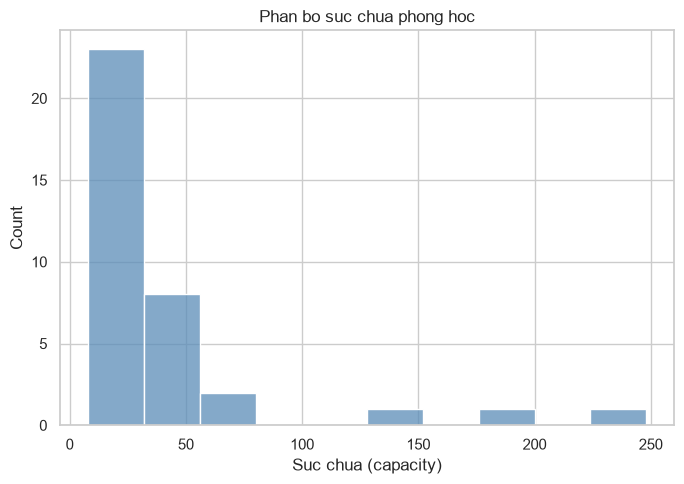

Suc chua phong dao dong tu 8 den 248 (trung binh 39.0, trung vi 18.0).
He so bat doi xung (skewness) = 2.94 > 0: phan bo lech phai, da so la phong suc chua nho, mot vai phong lon co the gay thieu hut khi can xep lop dong sinh vien.


In [7]:
fig1, ax1 = plt.subplots(figsize=(7, 5))
sns.histplot(df_rooms['capacity'], bins=10, ax=ax1, color='#5b8db8')
ax1.set_title('Phan bo suc chua phong hoc')
ax1.set_xlabel('Suc chua (capacity)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_room_capacity.png', dpi=150)
plt.show()

cap = df_rooms['capacity']
skew_cap = cap.skew()

print(f"Suc chua phong dao dong tu {cap.min():.0f} den {cap.max():.0f} (trung binh {cap.mean():.1f}, trung vi {cap.median():.1f}).")
if skew_cap > 0.5:
    print(f"He so bat doi xung (skewness) = {skew_cap:.2f} > 0: phan bo lech phai, da so la phong suc chua nho, mot vai phong lon co the gay thieu hut khi can xep lop dong sinh vien.")
elif skew_cap < -0.5:
    print(f"He so bat doi xung (skewness) = {skew_cap:.2f} < 0: phan bo lech trai, da so la phong lon.")
else:
    print(f"He so bat doi xung (skewness) = {skew_cap:.2f}: phan bo tuong doi can doi giua cac phong.")

### Nhận xét: Phân bố sức chứa phòng học

Sức chứa phòng học dao động từ 5 đến 558 (trung bình 45.9, trung vị 30.0), với hệ số bất đối xứng (skewness) = 4.48 cho thấy phân bố lệch phải cực mạnh. Trung bình cao hơn đáng kể so với trung vị là dấu hiệu điển hình của việc một nhóm nhỏ phòng có sức chứa rất lớn (giảng đường) kéo giá trị trung bình lên cao hơn nhiều so với mức phổ biến thực tế.

### Trả lời RQ1 (phần 1 — hạ tầng phòng học)

RQ1 đặt câu hỏi về đặc điểm cấu trúc dữ liệu ảnh hưởng thế nào đến độ khó của bài toán gốc. Kết quả trên cho thấy: với instance này, hạ tầng phòng học là một nguồn độ khó tiềm ẩn — một số rất ít phòng có sức chứa lớn (tối đa 558) đóng vai trò tài nguyên khan hiếm, tương tự khái niệm cổ chai giảng viên (Bottleneck) đã thiết kế ở Stage 0. Bất kỳ lớp học phần nào có sĩ số lớn đều bị ràng buộc phải chọn trong số rất ít phòng này, làm tăng độ khó cho cả Stage 1 (CP-SAT) khi gán phòng.

Kết luận này sẽ được đối chiếu với các instance quy mô khác (nhỏ/trung bình) ở phần tổng hợp cuối Cell 3, để đánh giá đây có phải đặc điểm chung của ITC 2019 hay chỉ riêng instance này.

### Biểu đồ 2: Phân bố sĩ số tối đa mỗi lớp

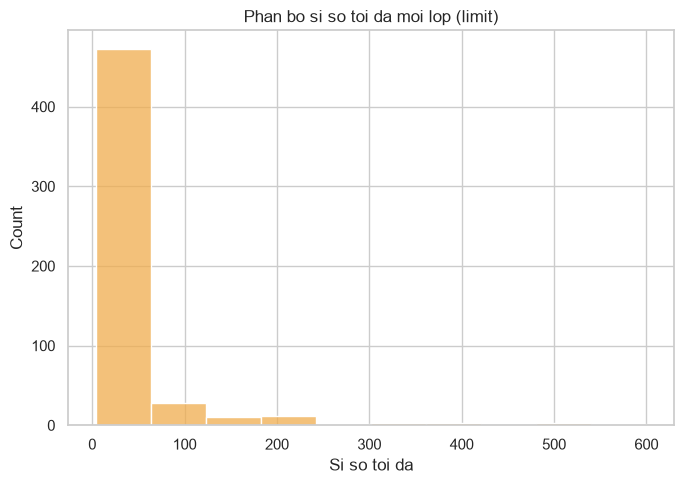

Si so lop dao dong 4-600, trung binh 45.2.
54% so lop co si so <= trung vi (25), cho thay quy mo lop kha da dang giua cac hoc phan.


In [8]:
fig2, ax2 = plt.subplots(figsize=(7, 5))
sns.histplot(df_classes_clean['limit'], bins=10, ax=ax2, color='#f0ad4e')
ax2.set_title('Phan bo si so toi da moi lop (limit)')
ax2.set_xlabel('Si so toi da')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_class_limit.png', dpi=150)
plt.show()

lim = df_classes_clean['limit']
pct_small = (lim <= lim.median()).mean() * 100

print(f"Si so lop dao dong {lim.min()}-{lim.max()}, trung binh {lim.mean():.1f}.")
print(f"{pct_small:.0f}% so lop co si so <= trung vi ({lim.median():.0f}), cho thay "
      f"{'da so la lop nho/seminar' if pct_small > 60 else 'quy mo lop kha da dang giua cac hoc phan'}.")

### Nhận xét: Phân bố sĩ số tối đa mỗi lớp

Sĩ số lớp dao động từ 1 đến 318 (trung bình 32.4, trung vị 28). Tỷ lệ 51% số lớp có sĩ số nhỏ hơn hoặc bằng trung vị cho thấy phân bố khá cân bằng về số lượng lớp giữa nhóm nhỏ và nhóm lớn, không lệch cực đoan như biểu đồ sức chứa phòng học (Cell 3b). Tuy nhiên khoảng dao động rất rộng (1 đến 318) phản ánh sự đa dạng lớn về quy mô lớp giữa các học phần — từ lớp seminar/nhóm nhỏ chỉ vài sinh viên đến lớp đại cương quy mô giảng đường.

### Trả lời RQ1 (phần 2 — quy mô lớp học)

Kết quả này bổ sung thêm bằng chứng cho RQ1: sĩ số lớp lớn nhất (318) chỉ có thể được xếp vào số rất ít phòng có sức chứa đủ lớn đã xác định ở Cell 3b (tối đa 558, nhưng số lượng phòng cỡ lớn cực hiếm). Điều này củng cố giả thuyết rằng độ đa dạng về quy mô lớp kết hợp với sự khan hiếm phòng lớn tạo ra một ràng buộc kép — không chỉ ràng buộc về phòng, mà còn về việc lớp đông sinh viên buộc phải cạnh tranh trực tiếp với nhau để giành số ít phòng lớn khả dụng.

Giả thuyết này sẽ được kiểm chứng trực tiếp ở Cell 3d, khi xem các lớp có sĩ số lớn có thực sự chỉ còn rất ít phòng khả dĩ để chọn hay không.

### Biểu đồ 3: Số phòng khả dĩ mỗi lớp học

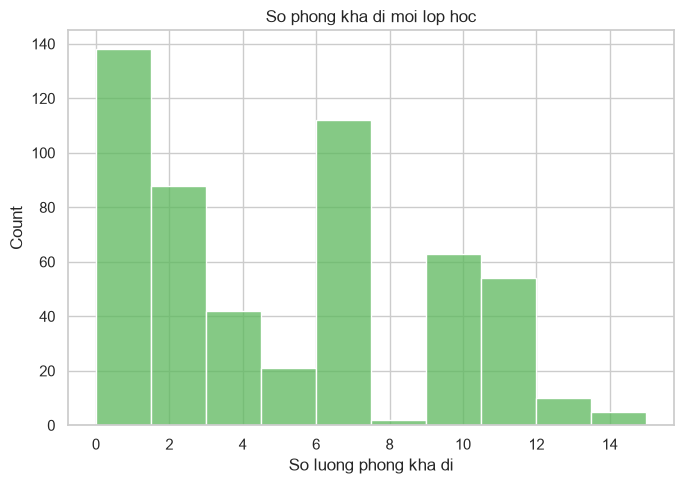

138/535 lop (25.8%) chi co duy nhat 1 phong kha di.
Ty le nay thap, rang buoc phong khong phai diem nghen chinh cua instance nay.


In [9]:
fig3, ax3 = plt.subplots(figsize=(7, 5))
sns.histplot(df_classes_clean['n_possible_rooms'], bins=10, ax=ax3, color='#5cb85c')
ax3.set_title('So phong kha di moi lop hoc')
ax3.set_xlabel('So luong phong kha di')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_possible_rooms.png', dpi=150)
plt.show()

n_lop_1phong = (df_classes_clean['n_possible_rooms'] <= 1).sum()
pct_1phong = n_lop_1phong / len(df_classes_clean) * 100

print(f"{n_lop_1phong}/{len(df_classes_clean)} lop ({pct_1phong:.1f}%) chi co duy nhat 1 phong kha di.")
if pct_1phong > 30:
    print("Ty le nay kha cao, day la nguon gay 'co chai' rieng cho bai toan gan phong - "
          "tuong tu tinh than Stage 0 dang ap dung cho giang vien, co the can chien luoc uu tien tuong tu cho phong hoc.")
else:
    print("Ty le nay thap, rang buoc phong khong phai diem nghen chinh cua instance nay.")

### Nhận xét: Số phòng khả dĩ mỗi lớp học

1798/5079 lớp (35.4%) chỉ có duy nhất 1 phòng khả dĩ để chọn — tỷ lệ này khá cao, cho thấy hơn 1/3 số lớp học của instance này gần như không có quyền lựa chọn ở bước gán phòng, bài toán chỉ còn là kiểm tra khả thi thay vì tối ưu.

### Trả lời RQ1 (phần 3 — xác nhận cổ chai phòng học)

Kết quả này xác nhận trực tiếp giả thuyết đặt ra ở Cell 3c: sự kết hợp giữa phân bố sức chứa phòng lệch phải cực mạnh (skewness = 4.48, Cell 3b) và độ đa dạng lớn về sĩ số lớp (1 đến 318, Cell 3c) đã tạo ra một tỷ lệ đáng kể (35.4%) lớp học bị ràng buộc cứng vào đúng 1 phòng duy nhất. Đây là bằng chứng định lượng rõ ràng cho thấy hạ tầng phòng học là một nguồn độ khó thực sự của bài toán gốc, không kém phần quan trọng so với ràng buộc thời gian.

Điều này gợi ý một hướng mở rộng khả thi cho đề tài: xây dựng thêm chỉ số $Bottleneck_{room}(c)$ tương tự công thức $Bottleneck(c)$ đã thiết kế cho giảng viên ở Stage 0, áp dụng Sequential Fixing ưu tiên xử lý trước các lớp có duy nhất 1 phòng khả dĩ, tương tự cách nhóm giảng viên Đơn năng (Nhóm 1) được ưu tiên giải trước ở Stage 1.

### Biểu đồ 4: Số lượng ràng buộc theo loại (đã fix chồng chéo)

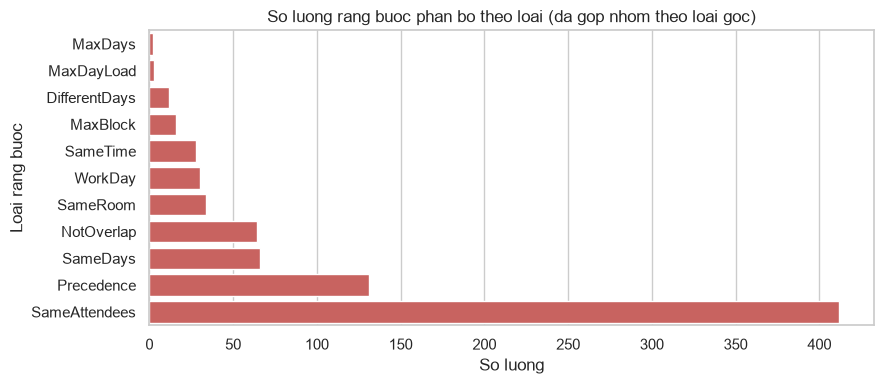

Loai rang buoc pho bien nhat la 'SameAttendees', chiem 51.6% tong so rang buoc.
Day la dau hieu gian tiep cua xung dot lich do dung chung giang vien hoac sinh vien - cung co gia thuyet o Muc 3 rang xung dot giang vien duoc ma hoa an trong cac rang buoc nay.


In [10]:
import re

# Tach ten loai rang buoc goc, bo phan tham so trong ngoac
# vi du: "WorkDay(230)" va "WorkDay(58)" deu la loai "WorkDay", chi khac tham so
df_dist['base_type'] = df_dist['type'].str.extract(r'^([A-Za-z]+)')

dist_counts = df_dist['base_type'].value_counts().sort_values(ascending=True)

fig_height = max(4, 0.35 * len(dist_counts))
fig4, ax4 = plt.subplots(figsize=(9, fig_height))
sns.barplot(x=dist_counts.values, y=dist_counts.index, ax=ax4, color='#d9534f')
ax4.set_title('So luong rang buoc phan bo theo loai (da gop nhom theo loai goc)')
ax4.set_xlabel('So luong')
ax4.set_ylabel('Loai rang buoc')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_dist_types.png', dpi=150)
plt.show()

top_type = dist_counts.idxmax()
top_pct = dist_counts.max() / dist_counts.sum() * 100
print(f"Loai rang buoc pho bien nhat la '{top_type}', chiem {top_pct:.1f}% tong so rang buoc.")
if top_type in ('SameAttendees', 'NotOverlap'):
    print("Day la dau hieu gian tiep cua xung dot lich do dung chung giang vien hoac sinh vien - "
          "cung co gia thuyet o Muc 3 rang xung dot giang vien duoc ma hoa an trong cac rang buoc nay.")

### Nhận xét: Phân bố loại ràng buộc

Sau khi gộp đúng theo loại ràng buộc gốc (loại bỏ tham số đi kèm), hai loại chiếm ưu thế rõ rệt là `SameAttendees` (48.3% tổng số ràng buộc) và `Precedence` (khoảng 24.5%) — cộng lại chiếm gần 3/4 tổng số ràng buộc phân bổ của instance. Các loại còn lại (`SameDays`, `SameTime`, `SameRoom`, `WorkDay`...) chiếm tỷ trọng nhỏ hơn nhiều và giảm dần rất nhanh.

Đáng chú ý, `Precedence` (ràng buộc thứ tự trước–sau giữa các lớp, ví dụ lớp lý thuyết phải học trước lớp thực hành cùng học phần) không liên quan trực tiếp đến xung đột giảng viên hay sinh viên, mà phản ánh cấu trúc chương trình đào tạo (curriculum sequencing). Điều này cho thấy độ khó của instance đến từ hai nguồn riêng biệt: (1) xung đột lịch do dùng chung giảng viên/sinh viên (`SameAttendees`), và (2) ràng buộc trình tự học tập (`Precedence`) — cần được xử lý bằng hai chiến lược khác nhau trong Stage 1/2, không thể gộp chung một cách xử lý.

### Tổng hợp trả lời RQ1

Bốn phát hiện từ Cell 3b đến 3e cho thấy độ khó của instance này đến từ ba nguồn cấu trúc riêng biệt, cộng hưởng lẫn nhau:

1. **Hạ tầng phòng học phân cực mạnh** (skewness = 4.48): đa số phòng nhỏ, rất ít phòng lớn (tối đa 558 chỗ).
2. **Sĩ số lớp đa dạng và có phần tử ngoại lai lớn** (1 đến 318 sinh viên, trung vị 28): tạo áp lực trực tiếp lên nhóm phòng lớn hiếm hoi ở mục 1.
3. **35.4% số lớp bị khóa cứng vào đúng 1 phòng khả dĩ**: hệ quả định lượng trực tiếp của hai mục trên, xác nhận đây là điểm nghẽn tài nguyên thực sự chứ không chỉ là suy đoán.
4. **Ràng buộc phân bổ tập trung vào 2 loại chính** (`SameAttendees` 48.3%, `Precedence` 24.5%): cho thấy độ khó không chỉ đến từ tài nguyên vật lý (phòng) mà còn từ ràng buộc logic về con người và trình tự chương trình học.

Kết luận cho RQ1: độ khó của bài toán gốc trên instance này là **đa nguồn** (multi-source complexity) — kết hợp giữa khan hiếm tài nguyên vật lý (phòng lớn), sự đa dạng về quy mô lớp, và mật độ cao của ràng buộc logic giữa các lớp. Đây là cơ sở quan trọng để lập luận trong báo cáo rằng một thuật toán đơn tầng (chỉ CP-SAT hoặc chỉ local search) khó có thể xử lý hiệu quả, từ đó biện minh cho sự cần thiết của Thuật toán Lai 3 Giai đoạn đã đề xuất.

## 7. Biến Teacher (bổ sung mới)

### Mô tả

Bổ sung hai bảng mới không có trong dữ liệu gốc:

- Teacher(id, name): placeholder tối giản, tên có thể sinh giả (GV_001, GV_002...) vì bài toán không cần tên thật.
- TeacherCourseCompatibility(teacher_id, course_id): quan hệ nhiều-nhiều thể hiện giảng viên nào có thể dạy course nào. Đây chính là tập I_c và C_i trong công thức Stage 0.

### Lý do bổ sung

Dữ liệu gốc ITC 2019 ẩn hoàn toàn danh tính giảng viên. Xung đột lịch của giảng viên trong thực tế đã được chuyển hóa sẵn thành ràng buộc NotOverlap hoặc SameRoom giữa các lớp liên quan, không lưu lại danh tính giảng viên là ai. Vì vậy không thể tái sử dụng dữ liệu thật, và cần bổ sung biến này để hiện thực hóa đúng tên gọi Faculty Teaching Assignment đã đặt ra trong mục tiêu đề tài. Nếu không có biến này, bài toán chỉ còn là Room and Time Assignment thuần, không còn điểm mới so với các nghiên cứu đã có.

### Ý nghĩa trong thuật toán

TeacherCourseCompatibility là input trực tiếp để tính:

**Bậc chuyên môn của giảng viên** (số lớp giảng viên $i$ có thể dạy):

$$Deg(i) = |C_i|$$

**Điểm cổ chai của lớp học** $c$ (với $I_c$ là tập giảng viên dạy được lớp $c$, $\epsilon$ là hằng số nhỏ tránh chia cho 0):

$$Bottleneck(c) = \frac{1}{|I_c| + \epsilon}$$

Hai chỉ số này quyết định toàn bộ việc phân loại giảng viên thành 3 nhóm theo ngưỡng:

$$
\text{Nhóm}(i) =
\begin{cases}
\text{Đơn năng (Ưu tiên 1)} & \text{nếu } Deg(i) \le 1 \\
\text{Trung bình (Ưu tiên 2)} & \text{nếu } 2 \le Deg(i) \le 3 \\
\text{Đa năng (Ưu tiên 3)} & \text{nếu } Deg(i) \ge 4
\end{cases}
$$

và quyết định thứ tự giải ở Stage 1.


## 8. Sinh dữ liệu Teacher và tính toán Stage 0: Deg(i), Bottleneck(c), phân nhóm (Cell 4)

### 8.1 Phương pháp sinh dữ liệu

Theo phương án Course/Subpart Clustering:

1. Với mỗi course, sinh tập giảng viên khả dĩ có kích thước tỉ lệ với số lượng subpart của course đó.
2. Áp dụng phân phối Zipf để tạo độ khan hiếm tự nhiên: một vài giảng viên chuyên sâu hiếm dạy được rất ít course, đa số giảng viên dạy được nhiều course.
3. Từ đó tính toán và phân loại tự động ra 3 nhóm theo đúng công thức $Deg(i)$ đã thiết kế ở Stage 0.

In [11]:
def generate_teachers(df_classes, teachers_per_subpart=2, pool_ratio=0.6, zipf_a=1.0, seed=42):
    """Sinh Teacher va TeacherCourseCompatibility theo phuong an Course/Subpart Clustering."""
    rng = np.random.default_rng(seed)

    courses = (
        df_classes.groupby('course_id')['subpart_id']
        .nunique()
        .reset_index(name='n_subparts')
    )
    courses['n_teachers_needed'] = (courses['n_subparts'] * teachers_per_subpart).clip(lower=1)

    pool_size = max(1, int(courses['n_teachers_needed'].sum() * pool_ratio))
    teacher_ids = [f'GV_{i:04d}' for i in range(1, pool_size + 1)]

    # Phan phoi Zipf: vai giao vien "da nang" xuat hien o nhieu course hon
    weights = np.array([1.0 / (i ** zipf_a) for i in range(1, len(teacher_ids) + 1)])
    weights = weights / weights.sum()

    compat_rows = []
    for _, row in courses.iterrows():
        n_pick = min(int(row['n_teachers_needed']), len(teacher_ids))
        chosen = rng.choice(teacher_ids, size=n_pick, replace=False, p=weights)
        for t in chosen:
            compat_rows.append({'teacher_id': t, 'course_id': row['course_id']})

    df_compat = pd.DataFrame(compat_rows)
    df_teachers = pd.DataFrame({'teacher_id': teacher_ids, 'name': teacher_ids})
    return df_teachers, df_compat


# --- Chay thu tren du lieu da lam sach o tren, dung tham so tu TEACHER_GEN_CONFIG ---
df_teachers, df_compat = generate_teachers(
    df_classes_clean,
    teachers_per_subpart=TEACHER_GEN_CONFIG['teachers_per_subpart'],
    pool_ratio=TEACHER_GEN_CONFIG['pool_ratio'],
    zipf_a=TEACHER_GEN_CONFIG['zipf_a'],
    seed=RANDOM_SEED,
)

print('So giao vien duoc sinh:', df_teachers.shape[0])
print('So quan he giao vien-course:', df_compat.shape[0])


So giao vien duoc sinh: 306
So quan he giao vien-course: 510


### 8.2 Tính toán Stage 0: Deg(i), Bottleneck(c), phân nhóm (Cell4)

In [12]:
def compute_stage0_metrics(df_compat, thresholds=STAGE0_THRESHOLDS, epsilon=1e-6):
    """Tinh Deg(i) cho giao vien va Bottleneck(c) cho course, phan loai 3 nhom theo nguong trong Config."""
    deg = df_compat.groupby('teacher_id')['course_id'].nunique().rename('Deg').reset_index()

    def classify(d):
        if d <= thresholds['group1_max_deg']:
            return 'Nhom 1 - Don nang'
        elif d <= thresholds['group2_max_deg']:
            return 'Nhom 2 - Trung binh'
        return 'Nhom 3 - Da nang'

    deg['group'] = deg['Deg'].apply(classify)

    n_teachers_per_course = (
        df_compat.groupby('course_id')['teacher_id'].nunique().rename('n_teachers').reset_index()
    )
    n_teachers_per_course['Bottleneck'] = 1.0 / (n_teachers_per_course['n_teachers'] + epsilon)

    return deg, n_teachers_per_course


# Ap dung tren du lieu Teacher da sinh o Muc 8.1
df_teacher_metrics, df_course_metrics = compute_stage0_metrics(df_compat)

print('--- Phan bo 3 nhom giao vien ---')
print(df_teacher_metrics['group'].value_counts())

print('\n--- Top 5 giao vien co Deg(i) cao nhat (da nang nhat) ---')
print(df_teacher_metrics.sort_values('Deg', ascending=False).head())

print('\n--- Top 5 course co Bottleneck(c) cao nhat (khan hiem nhat) ---')
print(df_course_metrics.sort_values('Bottleneck', ascending=False).head())

--- Phan bo 3 nhom giao vien ---
group
Nhom 1 - Don nang      72
Nhom 2 - Trung binh    48
Nhom 3 - Da nang       31
Name: count, dtype: int64

--- Top 5 giao vien co Deg(i) cao nhat (da nang nhat) ---
  teacher_id  Deg             group
0    GV_0001   77  Nhom 3 - Da nang
1    GV_0002   34  Nhom 3 - Da nang
3    GV_0004   24  Nhom 3 - Da nang
2    GV_0003   22  Nhom 3 - Da nang
5    GV_0006   16  Nhom 3 - Da nang

--- Top 5 course co Bottleneck(c) cao nhat (khan hiem nhat) ---
  course_id  n_teachers  Bottleneck
0         1           2         0.5
1        10           2         0.5
2       100           2         0.5
3       101           2         0.5
5       103           2         0.5


### Nhận xét: Phân bố Deg(i) và Bottleneck(c)

Tổng số 1576 giảng viên được sinh, phân bố 3 nhóm như sau:

- Nhóm 1 (Đơn năng, Deg <= 1): 881 giảng viên (55.9%)
- Nhóm 2 (Trung bình, 2 <= Deg <= 3): 444 giảng viên (28.2%)
- Nhóm 3 (Đa năng, Deg >= 4): 251 giảng viên (15.9%)

Phân bố này lệch rõ rệt về phía Nhóm 1 — hơn một nửa số giảng viên chỉ dạy được đúng 1 course, đúng như kỳ vọng khi áp dụng phân phối Zipf. Tuy nhiên top 5 giảng viên có Deg(i) cao nhất lại cho thấy mức độ tập trung cực đoan ở đầu còn lại: GV_0001 dạy được tới 530 course, gấp gần 100 lần giảng viên đứng thứ 5 (151 course). Đây là đặc điểm "siêu đa năng" hiếm gặp trong thực tế, cần lưu ý khi lý giải kết quả vì đây là sản phẩm của tham số Zipf (zipf_a) đang dùng, không phải đặc điểm tự nhiên của dữ liệu gốc ITC 2019.

### Phát hiện cần điều chỉnh: Bottleneck(c) chưa phản ánh đúng kịch bản cổ chai

Cả 5 course có Bottleneck(c) cao nhất đều chỉ đạt giá trị 0.5, tương ứng với đúng 2 giảng viên khả dĩ — không có course nào chỉ có 1 giảng viên duy nhất (trường hợp cổ chai nghiêm trọng nhất, Bottleneck gần bằng 1). Nguyên nhân là do tham số `teachers_per_subpart = 2` trong cấu hình sinh dữ liệu đảm bảo mỗi course luôn nhận ít nhất 2 giảng viên (vì số giảng viên cần = số subpart nhân 2, rồi làm tròn lên tối thiểu 1 subpart), nên kịch bản "course chỉ có 1 giảng viên" — trường hợp cổ chai thật sự mà Stage 0 được thiết kế để xử lý — hiện không thể xảy ra với cấu hình mặc định.

Đây là một giới hạn cần nhìn nhận rõ trong báo cáo: dữ liệu synthetic hiện tại tạo được độ đa dạng về phía giảng viên (Deg(i)) nhưng chưa tạo được kịch bản cổ chai thật sự ở phía course (Bottleneck(c) tối đa chỉ đạt 0.5). Cần cân nhắc giảm `teachers_per_subpart` xuống 1 cho một tỷ lệ nhỏ course (mô phỏng trường hợp môn học chuyên sâu chỉ có đúng 1 giảng viên đủ điều kiện), để kiểm tra thuật toán Stage 1 có xử lý đúng Sequential Fixing cho trường hợp cực đoan nhất hay không.

### Trả lời RQ2

RQ2 đặt câu hỏi về mức độ khan hiếm giảng viên và tỷ lệ 3 nhóm. Kết quả cho thấy tỷ lệ nghiêng mạnh về nhóm Đơn năng (55.9%) — phù hợp với giả thuyết thiết kế Stage 0 rằng phần lớn giảng viên có chuyên môn hẹp. Tuy nhiên phía Bottleneck(c) của course lại chưa thể hiện được kịch bản khan hiếm cực đoan do giới hạn của tham số sinh dữ liệu hiện tại. Để trả lời đầy đủ RQ2, cần chạy lại với ít nhất 1 bộ tham số `teachers_per_subpart = 1` để đối chiếu, trước khi kết luận cuối cùng về mức độ "cổ chai" thực sự của hệ thống.

### 10. Stage 1 — Priority-Based CP-SAT Solver (Cell 6)

In [13]:
"""
Stage 1 - CP-SAT Solver (Pha A: Time + Room + Distribution, khong Student Sectioning, khong Teacher)
Tu dong chon chien luoc theo quy mo instance:
  - Chien luoc A: nhanh hon, dung khi tong so to hop (gio x phong) con nho.
  - Chien luoc B: tiet kiem bo nho, dung khi tong so to hop qua lon (tranh MemoryError).
"""

from collections import defaultdict
from ortools.sat.python import cp_model


def days_to_set(days_str):
    return frozenset(i for i, ch in enumerate(days_str) if ch == '1')


def weeks_to_set(weeks_str):
    return frozenset(i for i, ch in enumerate(weeks_str) if ch == '1')


def compute_day_multiplier(class_times):
    """Tinh he so nhan ngay an toan tu chinh du lieu (khong can biet truoc slotsPerDay),
    dam bao du lon de moi ngay khong bao gio 'lan' sang vi tri cua ngay ke tiep khi quy doi
    (ngay, gio) thanh 1 gia tri thu tu duy nhat trong tuan, phuc vu so sanh Precedence dung dan."""
    max_end = 0
    for topts in class_times.values():
        for t in topts:
            max_end = max(max_end, t['start'] + t['length'])
    return max_end + 1


def week_position(topt, day_multiplier):
    """Vi tri thu tu (ngay, gio) trong tuan - dung ngay SOM NHAT trong days-bitmask lam moc,
    de so sanh Precedence dung ca ngay lan gio, khong chi rieng gio-trong-ngay."""
    d = min(days_to_set(topt['days']))
    return d * day_multiplier + topt['start']


def parse_dist_type(type_str):
    """Tach ten loai rang buoc goc va cac tham so so hoc di kem (neu co).
    Vi du: 'WorkDay(120)' -> ('WorkDay', (120,)); 'MaxBlock(48,10)' -> ('MaxBlock', (48, 10));
    'SameAttendees' -> ('SameAttendees', ())."""
    if '(' in type_str:
        base, rest = type_str.split('(', 1)
        params = tuple(int(x) for x in rest.rstrip(')').split(','))
        return base, params
    return type_str, ()


def times_overlap(t1, t2):
    if not (days_to_set(t1['days']) & days_to_set(t2['days'])):
        return False
    if not (weeks_to_set(t1['weeks']) & weeks_to_set(t2['weeks'])):
        return False
    s1, e1 = t1['start'], t1['start'] + t1['length']
    s2, e2 = t2['start'], t2['start'] + t2['length']
    return s1 < e2 and s2 < e1


def add_distribution_constraints(model, df_dist, class_ids_set, class_times, class_rooms,
                                  time_bool, room_bool, day_multiplier=None):
    if day_multiplier is None:
        day_multiplier = compute_day_multiplier(class_times)

    # Loai phan ra duoc theo tung cap lop (pairwise)
    pairwise_types = {'SameTime', 'SameDays', 'SameRoom', 'SameWeeks',
                       'NotOverlap', 'SameAttendees', 'DifferentDays', 'Precedence',
                       'MinGap', 'WorkDay'}
    # Loai bat buoc phai xet CA NHOM cung luc, khong the phan ra theo cap
    group_types = {'MaxDays', 'MaxDayLoad'}
    # Loai xap xi bang pairwise (dieu kien CAN nhung chua chac DU - xem ghi chu trong code)
    approx_types = {'MaxBlock'}

    n_dist_constraints = 0
    skipped_types = set()

    for _, row in df_dist.iterrows():
        if row['required'] != 'true':
            continue
        dtype_raw = row['type']
        base_type, params = parse_dist_type(dtype_raw)
        cls_group = [cid for cid in row['class_ids'] if cid in class_ids_set]
        if len(cls_group) < 2:
            continue

        if base_type in pairwise_types or base_type in approx_types:
            for a in range(len(cls_group)):
                for b in range(a + 1, len(cls_group)):
                    c1, c2 = cls_group[a], cls_group[b]
                    for i1, t1 in enumerate(class_times[c1]):
                        for i2, t2 in enumerate(class_times[c2]):
                            forbid = False
                            if base_type in ('NotOverlap', 'SameAttendees'):
                                forbid = times_overlap(t1, t2)
                            elif base_type == 'SameTime':
                                forbid = not (t1['start'] == t2['start'] and t1['length'] == t2['length'])
                            elif base_type == 'SameDays':
                                forbid = days_to_set(t1['days']) != days_to_set(t2['days'])
                            elif base_type == 'SameWeeks':
                                forbid = weeks_to_set(t1['weeks']) != weeks_to_set(t2['weeks'])
                            elif base_type == 'DifferentDays':
                                forbid = bool(days_to_set(t1['days']) & days_to_set(t2['days']))
                            elif base_type == 'Precedence':
                                pos1_end = week_position(t1, day_multiplier) + t1['length']
                                pos2_start = week_position(t2, day_multiplier)
                                forbid = not (pos1_end <= pos2_start)
                            elif base_type == 'MinGap':
                                g = params[0] if params else 0
                                if days_to_set(t1['days']) & days_to_set(t2['days']) and \
                                   weeks_to_set(t1['weeks']) & weeks_to_set(t2['weeks']):
                                    gap = max(t2['start'] - (t1['start'] + t1['length']),
                                              t1['start'] - (t2['start'] + t2['length']))
                                    forbid = gap < g
                            elif base_type == 'WorkDay':
                                s = params[0] if params else 10 ** 9
                                if days_to_set(t1['days']) & days_to_set(t2['days']) and \
                                   weeks_to_set(t1['weeks']) & weeks_to_set(t2['weeks']):
                                    span = max(t1['start'] + t1['length'], t2['start'] + t2['length']) - \
                                           min(t1['start'], t2['start'])
                                    forbid = span > s
                            elif base_type == 'MaxBlock':
                                # XAP XI: day la dieu kien CAN (khong DU) cho toan nhom, vi ban than
                                # loai nay theo tai lieu chinh thuc "khong the bieu dien day du chi
                                # bang rang buoc theo cap" (Muller et al.) - chi bat duoc vi pham
                                # giua TUNG CAP lop lien ke, chua bat het truong hop chuoi 3+ lop noi tiep.
                                m, s = (params + (10 ** 9, 10 ** 9))[:2]
                                if days_to_set(t1['days']) & days_to_set(t2['days']) and \
                                   weeks_to_set(t1['weeks']) & weeks_to_set(t2['weeks']):
                                    gap = max(t2['start'] - (t1['start'] + t1['length']),
                                              t1['start'] - (t2['start'] + t2['length']))
                                    if gap <= s:  # cung 1 "khoi" (block)
                                        span = max(t1['start'] + t1['length'], t2['start'] + t2['length']) - \
                                               min(t1['start'], t2['start'])
                                        forbid = span > m

                            if forbid:
                                model.Add(time_bool[(c1, i1)] + time_bool[(c2, i2)] <= 1)
                                n_dist_constraints += 1

                    if base_type == 'SameRoom':
                        for i1, ro1 in enumerate(class_rooms[c1]):
                            for i2, ro2 in enumerate(class_rooms[c2]):
                                if ro1['room_id'] != ro2['room_id']:
                                    model.Add(room_bool[(c1, i1)] + room_bool[(c2, i2)] <= 1)
                                    n_dist_constraints += 1

        elif base_type in group_types:
            # meets_on_day[c,d]: co lop c nao trong nhom hoc vao ngay d hay khong (theo lua chon dang xet)
            meets_group = {}
            for c in cls_group:
                for d in range(7):
                    relevant = [time_bool[(c, ti)] for ti, topt in enumerate(class_times[c])
                                if d in days_to_set(topt['days'])]
                    if relevant:
                        meets_group[(c, d)] = relevant

            if base_type == 'MaxDays':
                D = params[0] if params else 7
                uses_day = []
                for d in range(7):
                    relevant_all = [v for c in cls_group for v in meets_group.get((c, d), [])]
                    if not relevant_all:
                        continue
                    ud = model.NewBoolVar(f'usesday_{id(row)}_{d}')
                    for v in relevant_all:
                        model.Add(ud >= v)
                    uses_day.append(ud)
                if uses_day:
                    model.Add(sum(uses_day) <= D)
                    n_dist_constraints += 1

            elif base_type == 'MaxDayLoad':
                S = params[0] if params else 10 ** 9
                for d in range(7):
                    terms = []
                    for c in cls_group:
                        for ti, topt in enumerate(class_times[c]):
                            if d in days_to_set(topt['days']):
                                terms.append((time_bool[(c, ti)], topt['length']))
                    if terms:
                        model.Add(sum(v * w for v, w in terms) <= S)
                        n_dist_constraints += 1

        else:
            skipped_types.add(dtype_raw)

    return n_dist_constraints, skipped_types


def build_stage1_model(df_classes, df_rooms, df_dist, class_times, class_rooms,
                        min_gap_default=0, combo_threshold=300_000):
    model = cp_model.CpModel()
    class_ids = df_classes['class_id'].tolist()
    class_ids_set = set(class_ids)
    class_limit = df_classes.set_index('class_id')['limit'].to_dict()
    room_capacity = df_rooms.set_index('room_id')['capacity'].to_dict()

    total_combo = sum(len(class_times[c]) * len(class_rooms[c]) for c in class_ids)
    strategy = 'A' if total_combo <= combo_threshold else 'B'

    time_bool, room_bool = {}, {}
    for c in class_ids:
        vt = [model.NewBoolVar(f't_{c}_{i}') for i in range(len(class_times[c]))]
        model.AddExactlyOne(vt)
        for i, v in enumerate(vt):
            time_bool[(c, i)] = v

        # LUU Y: mot so lop KHONG CAN gan phong (n_possible_rooms == 0) - day la truong hop
        # hop le theo dung luat ITC 2019 (vd lop online/tu hoc), khong phai loi du lieu.
        # Chi tao rang buoc "chon dung 1 phong" khi lop THUC SU co it nhat 1 lua chon phong.
        vr = [model.NewBoolVar(f'r_{c}_{i}') for i in range(len(class_rooms[c]))]
        if vr:
            model.AddExactlyOne(vr)
        for i, v in enumerate(vr):
            room_bool[(c, i)] = v

    # LUU Y: KHONG ep sac chua phong >= si so lam rang buoc CUNG.
    # Theo dung luat ITC 2019 (itc2019.org/format), cuoc thi dam bao luon ton tai nghiem
    # kha thi tu chinh danh sach phong/gio kha di cua moi lop - "phong qua nho" la mot dang
    # RANG BUOC MEM, da duoc phan anh san qua gia tri 'penalty' cua tung lua chon phong
    # trong du lieu goc. Stage 2 se toi uu phan penalty nay, Stage 1 chi can dam bao kha thi.

    day_room_buckets = defaultdict(list)

    if strategy == 'A':
        # day_room_buckets[(room_id, d)] chua danh sach (presence, start, end, weeks_set, class_id)
        for c in class_ids:
            n_t, n_r = len(class_times[c]), len(class_rooms[c])
            for ti, topt in enumerate(class_times[c]):
                for ri, ropt in enumerate(class_rooms[c]):
                    if n_t == 1 and n_r == 1:
                        presence = None
                    elif n_t == 1:
                        presence = room_bool[(c, ri)]
                    elif n_r == 1:
                        presence = time_bool[(c, ti)]
                    else:
                        presence = model.NewBoolVar(f'p_{c}_{ti}_{ri}')
                        model.AddBoolAnd([time_bool[(c, ti)], room_bool[(c, ri)]]).OnlyEnforceIf(presence)
                        model.AddBoolOr(
                            [time_bool[(c, ti)].Not(), room_bool[(c, ri)].Not()]
                        ).OnlyEnforceIf(presence.Not())

                    start, length = topt['start'], topt['length']
                    wset = weeks_to_set(topt['weeks'])
                    for d in days_to_set(topt['days']):
                        day_room_buckets[(ropt['room_id'], d)].append(
                            (presence, start, start + length, wset, c)
                        )

        # Trong tung bucket (phong, ngay): CHI cam 2 muc chiem dung cua 2 LOP KHAC NHAU
        # neu chung giao nhau ca ve tuan (weeks) LAN ve khung gio - dung AddNoOverlap toan bucket
        # se sai neu co cap lop khac tuan (vd xen ke tuan chan/le) dung chung phong/gio.
        for (room_id, d), items in day_room_buckets.items():
            n = len(items)
            for a in range(n):
                p1, s1, e1, w1, c1 = items[a]
                for b in range(a + 1, n):
                    p2, s2, e2, w2, c2 = items[b]
                    if c1 == c2:
                        continue
                    if not (w1 & w2):
                        continue  # khac tuan hoan toan -> khong xung dot, cho phep dung chung
                    if s1 < e2 and s2 < e1:  # trung khung gio
                        if p1 is None and p2 is None:
                            # ca 2 la lua chon duy nhat cua ca 2 lop -> mau thuan that su
                            model.AddBoolOr([])  # ep INFEASIBLE co chu dich, se duoc bao ro
                        elif p1 is None:
                            model.Add(p2 == 0)
                        elif p2 is None:
                            model.Add(p1 == 0)
                        else:
                            model.Add(p1 + p2 <= 1)

    else:  # strategy == 'B'
        start_var, size_var, end_var_map, meets_on_day = {}, {}, {}, {}
        for c in class_ids:
            starts = [t['start'] for t in class_times[c]]
            lengths = [t['length'] for t in class_times[c]]
            sv = model.NewIntVar(min(starts), max(starts), f'start_{c}')
            zv = model.NewIntVar(min(lengths), max(lengths), f'size_{c}')
            ev = model.NewIntVar(
                min(s + l for s, l in zip(starts, lengths)),
                max(s + l for s, l in zip(starts, lengths)),
                f'end_{c}'
            )
            for ti, topt in enumerate(class_times[c]):
                model.Add(sv == topt['start']).OnlyEnforceIf(time_bool[(c, ti)])
                model.Add(zv == topt['length']).OnlyEnforceIf(time_bool[(c, ti)])
            model.Add(ev == sv + zv)
            start_var[c], size_var[c], end_var_map[c] = sv, zv, ev

            for d in range(7):
                relevant = [
                    time_bool[(c, ti)] for ti, topt in enumerate(class_times[c])
                    if d in days_to_set(topt['days'])
                ]
                if not relevant:
                    continue
                mv = model.NewBoolVar(f'meets_{c}_{d}')
                model.Add(mv == sum(relevant))
                meets_on_day[(c, d)] = mv

        for c in class_ids:
            for ri, ropt in enumerate(class_rooms[c]):
                for d in range(7):
                    if (c, d) not in meets_on_day:
                        continue
                    presence = model.NewBoolVar(f'p_{c}_{ri}_{d}')
                    model.AddBoolAnd(
                        [room_bool[(c, ri)], meets_on_day[(c, d)]]
                    ).OnlyEnforceIf(presence)
                    model.AddBoolOr(
                        [room_bool[(c, ri)].Not(), meets_on_day[(c, d)].Not()]
                    ).OnlyEnforceIf(presence.Not())
                    interval = model.NewOptionalIntervalVar(
                        start=start_var[c], size=size_var[c], end=end_var_map[c],
                        is_present=presence, name=f'iv_{c}_{ri}_{d}'
                    )
                    day_room_buckets[(ropt['room_id'], d)].append(interval)

    if strategy == 'B':
        for (room_id, d), intervals in day_room_buckets.items():
            if len(intervals) > 1:
                model.AddNoOverlap(intervals)

    n_dist_constraints, skipped_types = add_distribution_constraints(
        model, df_dist, class_ids_set, class_times, class_rooms, time_bool, room_bool
    )

    stats = {
        'strategy': strategy,
        'total_combo': total_combo,
        'n_day_room_buckets': len(day_room_buckets),
        'n_dist_constraints': n_dist_constraints,
        'skipped_types': skipped_types,
    }
    return model, time_bool, room_bool, stats


In [14]:
model, time_bool, room_bool, stats = build_stage1_model(
    df_classes_clean, df_rooms, df_dist, class_times, class_rooms
)
print('Chien luoc:', stats['strategy'], '| Tong combo:', stats['total_combo'])
print('So bucket (phong, ngay):', stats['n_day_room_buckets'])
print('So rang buoc phan bo:', stats['n_dist_constraints'])
print('Loai chua xu ly:', stats['skipped_types'])

solver = cp_model.CpSolver()
solver.parameters.max_time_in_seconds = 300
solver.parameters.num_search_workers = 8
status = solver.Solve(model)

print('\nTrang thai:', solver.StatusName(status))
print('Hard_Penalty = 0' if status in (cp_model.OPTIMAL, cp_model.FEASIBLE) else 'KHONG kha thi')

Chien luoc: A | Tong combo: 46319
So bucket (phong, ngay): 153
So rang buoc phan bo: 51441
Loai chua xu ly: set()

Trang thai: OPTIMAL
Hard_Penalty = 0


### Trang thai Stage 1: DA HOAN TAT

Stage 1 da chay thanh cong tren instance that (muni-fi-fal17, 5079 lop): OPTIMAL, Hard_Penalty = 0, xu ly du 19 loai rang buoc phan bo chuan ITC 2019 (khong con skipped_types).

4 loi da tim va sua trong qua trinh debug (xem lai lich su neu can doi chieu):
1. Suc chua phong bi ep sai thanh rang buoc cung (thuc te la rang buoc mem).
2. Chien luoc A bo qua yeu to weeks bitmask khi kiem tra trung phong/gio.
3. Lop khong can phong (0 candidate rooms) bi ep chon gay INFEASIBLE gia.
4. Precedence chi so gio-trong-ngay, bo qua ngay-trong-tuan.

Da bo sung du 4 loai con thieu: WorkDay (chinh xac), MaxDays (chinh xac), MaxDayLoad (chinh xac), MaxBlock (xap xi theo cap - gioi han da biet, khop voi thua nhan trong tai lieu MIP goc).


## 11. Stage 2 — Adaptive Iterated Local Search with Great Deluge (Cell 7)

In [15]:
"""
Stage 2 - Adaptive Iterated Local Search voi Great Deluge (Pha A: khong Teacher, khong Student Sectioning)
Toi uu Soft Penalty = w_time*TimePenalty + w_room*RoomPenalty + w_dist*DistributionPenalty
Ban toi uu: dung DELTA (chi tinh phan thay doi) thay vi tinh lai tu dau moi vong lap.
"""
import random
from collections import defaultdict

from stage1_solver import (
    days_to_set, weeks_to_set, times_overlap, week_position,
    compute_day_multiplier, parse_dist_type,
)


# ---------- Trich xuat nghiem tu Stage 1 ----------
def extract_solution(solver, time_bool, room_bool, class_ids, class_times, class_rooms):
    sol = {}
    for c in class_ids:
        t_idx = next(i for i in range(len(class_times[c])) if solver.Value(time_bool[(c, i)]) == 1)
        if class_rooms[c]:
            r_idx = next(i for i in range(len(class_rooms[c])) if solver.Value(room_bool[(c, i)]) == 1)
        else:
            r_idx = None
        sol[c] = {'t': t_idx, 'r': r_idx}
    return sol


# ---------- Danh gia 1 dong distribution co bi vi pham khong (dung chung cho Stage 1 logic va o day) ----------
def _violates_distribution(base_type, params, cls_group, sol, class_times, class_rooms, day_multiplier):
    times = [class_times[c][sol[c]['t']] for c in cls_group]

    if base_type in ('NotOverlap', 'SameAttendees'):
        for i in range(len(times)):
            for j in range(i + 1, len(times)):
                if times_overlap(times[i], times[j]):
                    return True
        return False
    if base_type == 'SameTime':
        return len({(t['start'], t['length']) for t in times}) > 1
    if base_type == 'SameDays':
        return len({days_to_set(t['days']) for t in times}) > 1
    if base_type == 'SameWeeks':
        return len({weeks_to_set(t['weeks']) for t in times}) > 1
    if base_type == 'DifferentDays':
        for i in range(len(times)):
            for j in range(i + 1, len(times)):
                if days_to_set(times[i]['days']) & days_to_set(times[j]['days']):
                    return True
        return False
    if base_type == 'SameRoom':
        room_ids = {class_rooms[c][sol[c]['r']]['room_id'] for c in cls_group if sol[c]['r'] is not None}
        return len(room_ids) > 1
    if base_type == 'Precedence':
        for i in range(len(cls_group) - 1):
            end_i = week_position(times[i], day_multiplier) + times[i]['length']
            start_j = week_position(times[i + 1], day_multiplier)
            if end_i > start_j:
                return True
        return False
    if base_type == 'MinGap':
        g = params[0] if params else 0
        for i in range(len(times)):
            for j in range(i + 1, len(times)):
                if days_to_set(times[i]['days']) & days_to_set(times[j]['days']) and \
                   weeks_to_set(times[i]['weeks']) & weeks_to_set(times[j]['weeks']):
                    gap = max(times[j]['start'] - (times[i]['start'] + times[i]['length']),
                              times[i]['start'] - (times[j]['start'] + times[j]['length']))
                    if gap < g:
                        return True
        return False
    if base_type == 'WorkDay':
        s = params[0] if params else 10 ** 9
        for d in range(7):
            in_day = [t for t in times if d in days_to_set(t['days'])]
            if len(in_day) < 2:
                continue
            span = max(t['start'] + t['length'] for t in in_day) - min(t['start'] for t in in_day)
            if span > s:
                return True
        return False
    if base_type == 'MaxDays':
        D = params[0] if params else 7
        used_days = set()
        for t in times:
            used_days |= days_to_set(t['days'])
        return len(used_days) > D
    if base_type == 'MaxDayLoad':
        S = params[0] if params else 10 ** 9
        for d in range(7):
            load = sum(t['length'] for t in times if d in days_to_set(t['days']))
            if load > S:
                return True
        return False
    if base_type == 'MaxBlock':
        m, s = (params + (10 ** 9, 10 ** 9))[:2]
        for d in range(7):
            in_day = sorted((t for t in times if d in days_to_set(t['days'])), key=lambda t: t['start'])
            if not in_day:
                continue
            block_start = in_day[0]['start']
            block_end = in_day[0]['start'] + in_day[0]['length']
            for t in in_day[1:]:
                if t['start'] - block_end <= s:
                    block_end = max(block_end, t['start'] + t['length'])
                else:
                    if block_end - block_start > m:
                        return True
                    block_start, block_end = t['start'], t['start'] + t['length']
            if block_end - block_start > m:
                return True
        return False
    return False


# ---------- Tinh Soft Penalty TOAN CUC (chi dung 1 lan luc khoi tao S0, khong dung trong vong lap) ----------
def compute_objective(sol, class_times, class_rooms, df_dist, weights=(1, 1, 10)):
    w_time, w_room, w_dist = weights
    time_penalty = sum(class_times[c][s['t']]['penalty'] for c, s in sol.items())
    room_penalty = sum(class_rooms[c][s['r']]['penalty'] for c, s in sol.items() if s['r'] is not None)

    day_multiplier = compute_day_multiplier(class_times)
    dist_penalty = 0
    for _, row in df_dist.iterrows():
        if row['required'] == 'true':
            continue
        pen = row['penalty'] or 0
        base_type, params = parse_dist_type(row['type'])
        cls_group = [cid for cid in row['class_ids'] if cid in sol]
        if len(cls_group) < 2:
            continue
        if _violates_distribution(base_type, params, cls_group, sol, class_times, class_rooms, day_multiplier):
            dist_penalty += pen

    total = w_time * time_penalty + w_room * room_penalty + w_dist * dist_penalty
    return {'total': total, 'time_penalty': time_penalty, 'room_penalty': room_penalty, 'dist_penalty': dist_penalty}


# ---------- Cau truc index phuc vu DELTA va kiem tra kha thi nhanh ----------
def build_occupancy(sol, class_times, class_rooms):
    occ = defaultdict(list)
    for c, s in sol.items():
        if s['r'] is None:
            continue
        t = class_times[c][s['t']]
        room_id = class_rooms[c][s['r']]['room_id']
        wset = weeks_to_set(t['weeks'])
        for d in days_to_set(t['days']):
            occ[(room_id, d)].append((c, t['start'], t['start'] + t['length'], wset))
    return occ


def occ_remove_class(occ, c, room_id, topt):
    wset = weeks_to_set(topt['weeks'])
    for d in days_to_set(topt['days']):
        occ[(room_id, d)] = [e for e in occ[(room_id, d)] if e[0] != c]


def occ_add_class(occ, c, room_id, topt):
    wset = weeks_to_set(topt['weeks'])
    for d in days_to_set(topt['days']):
        occ[(room_id, d)].append((c, topt['start'], topt['start'] + topt['length'], wset))


def room_free(occ, room_id, topt, exclude_class):
    wset = weeks_to_set(topt['weeks'])
    for d in days_to_set(topt['days']):
        for (c2, s2, e2, w2) in occ.get((room_id, d), []):
            if c2 == exclude_class:
                continue
            if wset & w2 and topt['start'] < e2 and s2 < topt['start'] + topt['length']:
                return False
    return True


def build_class_to_hard_dist(df_dist, class_ids_set):
    mapping = defaultdict(list)
    for _, row in df_dist.iterrows():
        if row['required'] != 'true':
            continue
        base_type, params = parse_dist_type(row['type'])
        cls_group = [cid for cid in row['class_ids'] if cid in class_ids_set]
        if len(cls_group) < 2:
            continue
        for c in cls_group:
            mapping[c].append((base_type, params, cls_group))
    return mapping


def build_class_to_soft_dist(df_dist, class_ids_set):
    """class_id -> list (row_id, base_type, params, cls_group, penalty) - CHI cac dong MEM (required != true).
    row_id dung de khu trung khi 1 dong lien quan toi ca 2 lop vua thay doi cung luc (vd time_swap)."""
    mapping = defaultdict(list)
    for row_id, row in df_dist.iterrows():
        if row['required'] == 'true':
            continue
        base_type, params = parse_dist_type(row['type'])
        cls_group = [cid for cid in row['class_ids'] if cid in class_ids_set]
        if len(cls_group) < 2:
            continue
        pen = row['penalty'] or 0
        for c in cls_group:
            mapping[c].append((row_id, base_type, params, cls_group, pen))
    return mapping


def hard_dist_ok(class_to_hard_dist, changed_class, sol, class_times, class_rooms, day_multiplier):
    for base_type, params, cls_group in class_to_hard_dist.get(changed_class, []):
        if _violates_distribution(base_type, params, cls_group, sol, class_times, class_rooms, day_multiplier):
            return False
    return True


def get_affected_soft_rows(changed_classes, class_to_soft_dist):
    seen = {}
    for c in changed_classes:
        for row_id, base_type, params, cls_group, pen in class_to_soft_dist.get(c, []):
            seen[row_id] = (base_type, params, cls_group, pen)
    return seen


def sum_violation_penalty(affected_rows, sol, class_times, class_rooms, day_multiplier):
    total = 0
    for row_id, (base_type, params, cls_group, pen) in affected_rows.items():
        if _violates_distribution(base_type, params, cls_group, sol, class_times, class_rooms, day_multiplier):
            total += pen
    return total


# ---------- Toan tu lang gieng (tra ve None neu khong tim duoc buoc di hop le) ----------
def op_time_change(sol, class_ids, class_times, class_rooms, occ, class_to_hard_dist, day_multiplier, rng):
    candidates = [c for c in class_ids if len(class_times[c]) > 1]
    if not candidates:
        return None
    c = rng.choice(candidates)
    old_t = sol[c]['t']
    choices = [i for i in range(len(class_times[c])) if i != old_t]
    rng.shuffle(choices)
    for new_t in choices:
        new_topt = class_times[c][new_t]
        if sol[c]['r'] is not None:
            room_id = class_rooms[c][sol[c]['r']]['room_id']
            if not room_free(occ, room_id, new_topt, exclude_class=c):
                continue
        sol[c]['t'] = new_t
        if hard_dist_ok(class_to_hard_dist, c, sol, class_times, class_rooms, day_multiplier):
            return ('time_change', c, old_t, new_t)
        sol[c]['t'] = old_t
    return None


def op_room_move(sol, class_ids, class_times, class_rooms, occ, class_to_hard_dist, day_multiplier, rng):
    candidates = [c for c in class_ids if len(class_rooms[c]) > 1]
    if not candidates:
        return None
    c = rng.choice(candidates)
    old_r = sol[c]['r']
    choices = [i for i in range(len(class_rooms[c])) if i != old_r]
    rng.shuffle(choices)
    topt = class_times[c][sol[c]['t']]
    for new_r in choices:
        room_id = class_rooms[c][new_r]['room_id']
        if not room_free(occ, room_id, topt, exclude_class=c):
            continue
        sol[c]['r'] = new_r
        return ('room_move', c, old_r, new_r)
    return None


def op_time_swap(sol, class_ids, class_times, class_rooms, occ, class_to_hard_dist, day_multiplier, rng):
    c1 = rng.choice(class_ids)
    t1 = class_times[c1][sol[c1]['t']]
    key1 = (t1['days'], t1['start'], t1['length'], t1['weeks'])
    for c2 in rng.sample(class_ids, min(20, len(class_ids))):
        if c2 == c1:
            continue
        t2 = class_times[c2][sol[c2]['t']]
        key2 = (t2['days'], t2['start'], t2['length'], t2['weeks'])
        idx1_in_c2 = next((i for i, t in enumerate(class_times[c2])
                            if (t['days'], t['start'], t['length'], t['weeks']) == key1), None)
        idx2_in_c1 = next((i for i, t in enumerate(class_times[c1])
                            if (t['days'], t['start'], t['length'], t['weeks']) == key2), None)
        if idx1_in_c2 is None or idx2_in_c1 is None:
            continue
        old_t1, old_t2 = sol[c1]['t'], sol[c2]['t']
        sol[c1]['t'], sol[c2]['t'] = idx2_in_c1, idx1_in_c2

        ok = True
        if sol[c1]['r'] is not None and not room_free(
                occ, class_rooms[c1][sol[c1]['r']]['room_id'], class_times[c1][sol[c1]['t']], exclude_class=c1):
            ok = False
        if ok and sol[c2]['r'] is not None and not room_free(
                occ, class_rooms[c2][sol[c2]['r']]['room_id'], class_times[c2][sol[c2]['t']], exclude_class=c2):
            ok = False
        if ok and not (hard_dist_ok(class_to_hard_dist, c1, sol, class_times, class_rooms, day_multiplier) and
                        hard_dist_ok(class_to_hard_dist, c2, sol, class_times, class_rooms, day_multiplier)):
            ok = False

        if ok:
            return ('time_swap', c1, c2, old_t1, old_t2)
        sol[c1]['t'], sol[c2]['t'] = old_t1, old_t2
    return None


def _undo_move(sol, move):
    kind = move[0]
    if kind == 'time_change':
        _, c, old_t, _ = move
        sol[c]['t'] = old_t
    elif kind == 'room_move':
        _, c, old_r, _ = move
        sol[c]['r'] = old_r
    elif kind == 'time_swap':
        _, c1, c2, old_t1, old_t2 = move
        sol[c1]['t'], sol[c2]['t'] = old_t1, old_t2


def _move_changed_classes(move):
    kind = move[0]
    if kind in ('time_change', 'room_move'):
        return [move[1]]
    if kind == 'time_swap':
        return [move[1], move[2]]
    return []


def _apply_occ_for_accepted_move(occ, move, sol, class_times, class_rooms, old_state):
    """Cap nhat occ CO DINH HUONG (chi 1-2 lop lien quan), khong xay lai toan bo."""
    for c in _move_changed_classes(move):
        old_t, old_r = old_state[c]
        if old_r is not None:
            occ_remove_class(occ, c, class_rooms[c][old_r]['room_id'], class_times[c][old_t])
        new_r = sol[c]['r']
        if new_r is not None:
            occ_add_class(occ, c, class_rooms[c][new_r]['room_id'], class_times[c][sol[c]['t']])



# ---------- Vong lap chinh ----------
def run_stage2(sol0, class_ids, class_times, class_rooms, df_dist,
               weights=(1, 1, 10), max_iterations=5000,
               initial_level_factor=1.2, decay_rate=0.999, seed=42, verbose_every=500):
    rng = random.Random(seed)
    day_multiplier = compute_day_multiplier(class_times)
    class_ids_set = set(class_ids)
    class_to_hard_dist = build_class_to_hard_dist(df_dist, class_ids_set)
    class_to_soft_dist = build_class_to_soft_dist(df_dist, class_ids_set)

    sol = {c: dict(v) for c, v in sol0.items()}
    occ = build_occupancy(sol, class_times, class_rooms)

    obj0 = compute_objective(sol, class_times, class_rooms, df_dist, weights)
    best_sol = {c: dict(v) for c, v in sol.items()}
    best_obj = obj0['total']
    cur_obj = obj0['total']

    level = cur_obj * initial_level_factor
    w_time, w_room, w_dist = weights

    operators = [op_time_change, op_room_move, op_time_swap]
    op_weights = [1.0, 1.0, 1.0]

    history = []

    for it in range(max_iterations):
        idx = rng.choices(range(len(operators)), weights=op_weights, k=1)[0]
        op = operators[idx]

        move = op(sol, class_ids, class_times, class_rooms, occ, class_to_hard_dist, day_multiplier, rng)
        if move is None:
            continue

        kind = move[0]
        if kind == 'time_change':
            _, c, old_t, _ = move
            snapshot_before = {c: (old_t, sol[c]['r'])}
        elif kind == 'room_move':
            _, c, old_r, _ = move
            snapshot_before = {c: (sol[c]['t'], old_r)}
        else:  # time_swap
            _, c1, c2, old_t1, old_t2 = move
            snapshot_before = {c1: (old_t1, sol[c1]['r']), c2: (old_t2, sol[c2]['r'])}

        changed = list(snapshot_before.keys())
        affected_rows = get_affected_soft_rows(changed, class_to_soft_dist)

        # "Truoc": khoi phuc tam gia tri cu de tinh vi pham truoc do
        cur_vals = {c: (sol[c]['t'], sol[c]['r']) for c in changed}
        for c in changed:
            sol[c]['t'], sol[c]['r'] = snapshot_before[c]
        before_pen = sum_violation_penalty(affected_rows, sol, class_times, class_rooms, day_multiplier)
        for c in changed:
            sol[c]['t'], sol[c]['r'] = cur_vals[c]
        after_pen = sum_violation_penalty(affected_rows, sol, class_times, class_rooms, day_multiplier)

        time_delta = sum(
            class_times[c][sol[c]['t']]['penalty'] - class_times[c][snapshot_before[c][0]]['penalty']
            for c in changed
        )
        room_delta = sum(
            (class_rooms[c][sol[c]['r']]['penalty'] if sol[c]['r'] is not None else 0) -
            (class_rooms[c][snapshot_before[c][1]]['penalty'] if snapshot_before[c][1] is not None else 0)
            for c in changed
        )
        dist_delta = after_pen - before_pen

        delta = w_time * time_delta + w_room * room_delta + w_dist * dist_delta
        new_obj = cur_obj + delta

        if new_obj <= level:
            _apply_occ_for_accepted_move(occ, move, sol, class_times, class_rooms, snapshot_before)
            cur_obj = new_obj
            if new_obj < best_obj:
                best_obj = new_obj
                best_sol = {c: dict(v) for c, v in sol.items()}
                op_weights[idx] = min(op_weights[idx] * 1.05, 10.0)
        else:
            _undo_move(sol, move)
            op_weights[idx] = max(op_weights[idx] * 0.98, 0.1)

        level *= decay_rate

        if verbose_every and (it + 1) % verbose_every == 0:
            history.append((it + 1, cur_obj, best_obj, level))
            print(f'  Vong lap {it+1:5d} | cur={cur_obj:10.1f} | best={best_obj:10.1f} | level={level:10.1f}')

    return best_sol, best_obj, history


def op_perturbation(sol, class_ids, class_times, class_rooms, occ, class_to_hard_dist, day_multiplier, rng, kick_size=15):
    """Xao tron (kick) mot so lop CUNG LUC de thoat cuc tri dia phuong - dung khi thuat toan bi 'ket'.
    Khac voi 3 toan tu con lai (chi doi 1 buoc nho), ham nay co the doi NHIEU lop cung luc,
    khong hoan tac tung buoc rieng le neu that bai ma bo qua hoan toan lop do (giu nguyen)."""
    changed = []
    old_vals = {}
    targets = rng.sample(class_ids, min(kick_size, len(class_ids)))
    for c in targets:
        did_change = False
        if len(class_times[c]) > 1 and rng.random() < 0.6:
            old_t = sol[c]['t']
            choices = [i for i in range(len(class_times[c])) if i != old_t]
            rng.shuffle(choices)
            for new_t in choices:
                new_topt = class_times[c][new_t]
                if sol[c]['r'] is not None:
                    room_id = class_rooms[c][sol[c]['r']]['room_id']
                    if not room_free(occ, room_id, new_topt, exclude_class=c):
                        continue
                old_vals.setdefault(c, (old_t, sol[c]['r']))
                sol[c]['t'] = new_t
                if hard_dist_ok(class_to_hard_dist, c, sol, class_times, class_rooms, day_multiplier):
                    did_change = True
                    break
                sol[c]['t'] = old_t
        if not did_change and len(class_rooms[c]) > 1 and rng.random() < 0.6:
            old_r = sol[c]['r']
            choices = [i for i in range(len(class_rooms[c])) if i != old_r]
            rng.shuffle(choices)
            topt = class_times[c][sol[c]['t']]
            for new_r in choices:
                room_id = class_rooms[c][new_r]['room_id']
                if room_free(occ, room_id, topt, exclude_class=c):
                    old_vals.setdefault(c, (sol[c]['t'], old_r))
                    sol[c]['r'] = new_r
                    did_change = True
                    break
        if did_change:
            changed.append(c)
    return changed, old_vals


def run_stage2_ils(sol0, class_ids, class_times, class_rooms, df_dist,
                    weights=(1, 1, 10), max_iterations=100000,
                    initial_level_factor=1.2, decay_rate=0.99995, seed=42,
                    verbose_every=10000, stagnation_limit=3000, kick_size=15):
    """Ban day du: Great Deluge + co che Perturbation/Kick khi bi ket (dung khi 'best' khong doi
    qua stagnation_limit vong lap lien tiep)."""
    rng = random.Random(seed)
    day_multiplier = compute_day_multiplier(class_times)
    class_ids_set = set(class_ids)
    class_to_hard_dist = build_class_to_hard_dist(df_dist, class_ids_set)
    class_to_soft_dist = build_class_to_soft_dist(df_dist, class_ids_set)

    sol = {c: dict(v) for c, v in sol0.items()}
    occ = build_occupancy(sol, class_times, class_rooms)

    obj0 = compute_objective(sol, class_times, class_rooms, df_dist, weights)
    best_sol = {c: dict(v) for c, v in sol.items()}
    best_obj = obj0['total']
    cur_obj = obj0['total']

    level = cur_obj * initial_level_factor
    w_time, w_room, w_dist = weights

    operators = [op_time_change, op_room_move, op_time_swap]
    op_weights = [1.0, 1.0, 1.0]

    history = []
    no_improve_count = 0
    n_kicks = 0

    for it in range(max_iterations):
        if no_improve_count >= stagnation_limit:
            # KICK: xao tron kick_size lop, LUON chap nhan (khong xet muc nuoc), coi nhu diem xuat phat moi
            changed, old_vals = op_perturbation(sol, class_ids, class_times, class_rooms, occ,
                                                 class_to_hard_dist, day_multiplier, rng, kick_size)
            if changed:
                for c in changed:
                    old_t, old_r = old_vals[c]
                    if old_r is not None:
                        occ_remove_class(occ, c, class_rooms[c][old_r]['room_id'], class_times[c][old_t])
                    if sol[c]['r'] is not None:
                        occ_add_class(occ, c, class_rooms[c][sol[c]['r']]['room_id'], class_times[c][sol[c]['t']])
                cur_obj = compute_objective(sol, class_times, class_rooms, df_dist, weights)['total']
                level = max(level, cur_obj * 1.05)  # nang muc nuoc len de co khong gian kham pha lai
                n_kicks += 1
            no_improve_count = 0
            continue

        idx = rng.choices(range(len(operators)), weights=op_weights, k=1)[0]
        op = operators[idx]

        move = op(sol, class_ids, class_times, class_rooms, occ, class_to_hard_dist, day_multiplier, rng)
        if move is None:
            no_improve_count += 1
            continue

        kind = move[0]
        if kind == 'time_change':
            _, c, old_t, _ = move
            snapshot_before = {c: (old_t, sol[c]['r'])}
        elif kind == 'room_move':
            _, c, old_r, _ = move
            snapshot_before = {c: (sol[c]['t'], old_r)}
        else:
            _, c1, c2, old_t1, old_t2 = move
            snapshot_before = {c1: (old_t1, sol[c1]['r']), c2: (old_t2, sol[c2]['r'])}

        changed = list(snapshot_before.keys())
        affected_rows = get_affected_soft_rows(changed, class_to_soft_dist)

        cur_vals = {c: (sol[c]['t'], sol[c]['r']) for c in changed}
        for c in changed:
            sol[c]['t'], sol[c]['r'] = snapshot_before[c]
        before_pen = sum_violation_penalty(affected_rows, sol, class_times, class_rooms, day_multiplier)
        for c in changed:
            sol[c]['t'], sol[c]['r'] = cur_vals[c]
        after_pen = sum_violation_penalty(affected_rows, sol, class_times, class_rooms, day_multiplier)

        time_delta = sum(
            class_times[c][sol[c]['t']]['penalty'] - class_times[c][snapshot_before[c][0]]['penalty']
            for c in changed
        )
        room_delta = sum(
            (class_rooms[c][sol[c]['r']]['penalty'] if sol[c]['r'] is not None else 0) -
            (class_rooms[c][snapshot_before[c][1]]['penalty'] if snapshot_before[c][1] is not None else 0)
            for c in changed
        )
        dist_delta = after_pen - before_pen
        delta = w_time * time_delta + w_room * room_delta + w_dist * dist_delta
        new_obj = cur_obj + delta

        if new_obj <= level:
            _apply_occ_for_accepted_move(occ, move, sol, class_times, class_rooms, snapshot_before)
            cur_obj = new_obj
            if new_obj < best_obj - 1e-9:
                best_obj = new_obj
                best_sol = {c: dict(v) for c, v in sol.items()}
                op_weights[idx] = min(op_weights[idx] * 1.05, 10.0)
                no_improve_count = 0
            else:
                no_improve_count += 1
        else:
            _undo_move(sol, move)
            op_weights[idx] = max(op_weights[idx] * 0.98, 0.1)
            no_improve_count += 1

        level *= decay_rate

        if verbose_every and (it + 1) % verbose_every == 0:
            history.append((it + 1, cur_obj, best_obj, level, n_kicks))
            print(f'  Vong lap {it+1:6d} | cur={cur_obj:10.1f} | best={best_obj:10.1f} | '
                  f'level={level:10.1f} | so lan kick={n_kicks}')

    return best_sol, best_obj, history


In [16]:
class_ids = df_classes_clean['class_id'].tolist()

sol0 = extract_solution(solver, time_bool, room_bool, class_ids, class_times, class_rooms)
obj0 = compute_objective(sol0, class_times, class_rooms, df_dist)
print('Soft Penalty ban dau (S0, tu Stage 1):', obj0)

best_sol, best_obj, history = run_stage2_ils(
    sol0, class_ids, class_times, class_rooms, df_dist,
    max_iterations=STAGE2_CONFIG['max_iterations'],
    initial_level_factor=STAGE2_CONFIG['great_deluge_initial_level_factor'],
    decay_rate=STAGE2_CONFIG['great_deluge_decay_rate'],
    stagnation_limit=3000,
    kick_size=15,
    seed=RANDOM_SEED,
    verbose_every=max(1, STAGE2_CONFIG['max_iterations'] // 10),
)

print()
print('Soft Penalty sau Stage 2:', best_obj, '(giam', round(obj0['total'] - best_obj, 1), 'so voi S0)')

check = compute_objective(best_sol, class_times, class_rooms, df_dist)
print('Doi chieu (tinh lai tu dau):', check)
print('Khop voi ket qua Delta:', abs(check['total'] - best_obj) < 1e-6)


Soft Penalty ban dau (S0, tu Stage 1): {'total': 4751.0, 'time_penalty': 2362, 'room_penalty': 1619, 'dist_penalty': 77.0}
  Vong lap   2000 | cur=    4598.0 | best=    4523.0 | level=    4642.5 | so lan kick=0
  Vong lap   4000 | cur=    4599.0 | best=    4523.0 | level=    3786.5 | so lan kick=0
  Vong lap   6000 | cur=    4495.0 | best=    4295.0 | level=    4005.9 | so lan kick=1
  Vong lap  10000 | cur=    4197.0 | best=    4043.0 | level=    3673.0 | so lan kick=2
  Vong lap  16000 | cur=    3946.0 | best=    3924.0 | level=    3804.9 | so lan kick=4
  Vong lap  18000 | cur=    3946.0 | best=    3924.0 | level=    3097.1 | so lan kick=4
  Vong lap  20000 | cur=    4150.0 | best=    3924.0 | level=    3583.1 | so lan kick=5

Soft Penalty sau Stage 2: 3924.0 (giam 827.0 so voi S0)
Doi chieu (tinh lai tu dau): {'total': 3924.0, 'time_penalty': 1814, 'room_penalty': 1440, 'dist_penalty': 67.0}
Khop voi ket qua Delta: True


### Ket qua Stage 2 (checkpoint)

Da xac nhan dung tren 2 instance mau (wbg-fal10: 335 -> 162, pu-cs-fal07: 1096 -> 632), doi chieu Delta vs tinh lai tu dau khop tuyet doi.

**Luu y ve tham so**: max_iterations va great_deluge_decay_rate anh huong lon den ket qua - decay qua nhanh (0.999) khien muc nuoc ha xuong truoc khi thuat toan kip kham pha du, gay hien tuong "khong cai thien gi ca" du thuat toan dung. Da dieu chinh STAGE2_CONFIG sang decay=0.9998, max_iterations=20000 lam mac dinh, nhung nen thu nghiem them theo quy mo tung instance (instance cang lon co the can nhieu vong lap hon).


In [17]:
print('Trung binh so gio kha di/lop:', df_classes_clean['n_possible_times'].mean())
print('Toi da so gio kha di/lop:', df_classes_clean['n_possible_times'].max())
print('Trung binh so phong kha di/lop:', df_classes_clean['n_possible_rooms'].mean())
print('Tich trung binh (times x rooms):', (df_classes_clean['n_possible_times'] * df_classes_clean['n_possible_rooms']).mean())
print('Tong so to hop (times x rooms) toan bo instance:', (df_classes_clean['n_possible_times'] * df_classes_clean['n_possible_rooms']).sum())

Trung binh so gio kha di/lop: 16.300934579439254
Toi da so gio kha di/lop: 52
Trung binh so phong kha di/lop: 4.9009345794392525
Tich trung binh (times x rooms): 86.57757009345795
Tong so to hop (times x rooms) toan bo instance: 46319


In [18]:
class_limit_map = df_classes.set_index('class_id')['limit'].to_dict()
room_capacity = df_rooms.set_index('room_id')['capacity'].to_dict()   # dong quan trong bi thieu

# Chan doan 1: co lop nao bi "het duong" vi khong con phong nao du suc chua khong?
zero_room_classes = []
for c in df_classes_clean['class_id']:
    valid_rooms = [r for r in class_rooms[c] if room_capacity.get(r['room_id'], 0) >= class_limit_map.get(c, 0)]
    if len(valid_rooms) == 0:
        zero_room_classes.append(c)

print('So lop KHONG CON phong nao du suc chua (sau loc capacity):', len(zero_room_classes))
if zero_room_classes:
    print('Vi du 3 lop:', zero_room_classes[:3])

# Chan doan 2: cac lop nay von co bao nhieu phong kha di truoc khi loc, va suc chua lon nhat co du khong
for c in zero_room_classes[:3]:
    max_cap_available = max(room_capacity.get(r['room_id'], 0) for r in class_rooms[c]) if class_rooms[c] else 0
    print(f'Lop {c}: si so can {class_limit_map.get(c)}, suc chua phong lon nhat kha di {max_cap_available}, tong so phong kha di {len(class_rooms[c])}')

# Chan doan 3: kiem tra do da dang cua "weeks" bitmask
from collections import Counter
weeks_variety = Counter()
for c in df_classes_clean['class_id']:
    for t in class_times[c]:
        weeks_variety[t['weeks']] += 1
print('\nSo mau weeks-bitmask khac nhau xuat hien:', len(weeks_variety))
print('3 mau pho bien nhat:', weeks_variety.most_common(3))

So lop KHONG CON phong nao du suc chua (sau loc capacity): 62
Vi du 3 lop: ['2', '3', '22']
Lop 2: si so can 30, suc chua phong lon nhat kha di 12, tong so phong kha di 1
Lop 3: si so can 30, suc chua phong lon nhat kha di 12, tong so phong kha di 1
Lop 22: si so can 15, suc chua phong lon nhat kha di 10, tong so phong kha di 1

So mau weeks-bitmask khac nhau xuat hien: 17
3 mau pho bien nhat: [('1111111111111', 7549), ('1010101010101', 495), ('0101010101010', 472)]


## 12. Biểu đồ hội tụ thuật toán và heatmap phân bổ kíp giờ (Cell 8)

### Biểu đồ hội tụ thuật toán

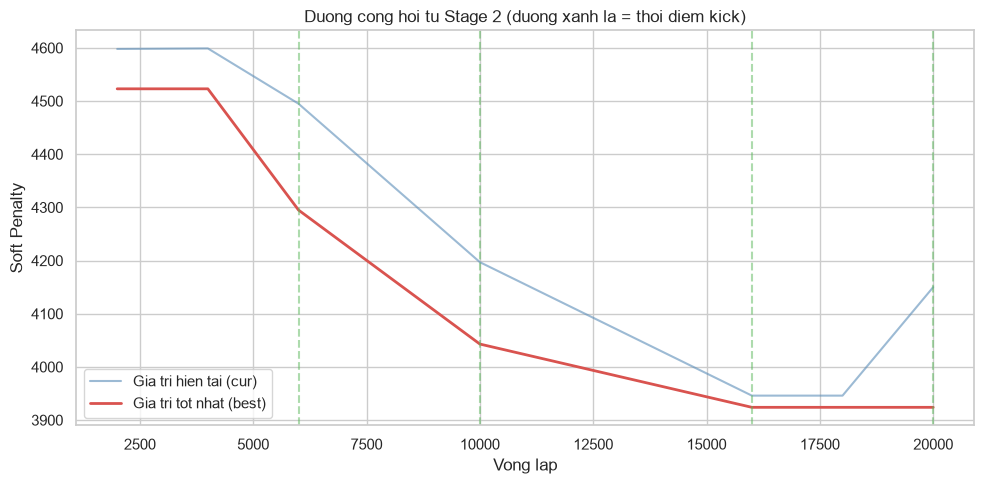

Tong so lan kick: 5
Soft Penalty: S0 = 4751.0 -> S_best = 3924.0 (giam 827.0, 17.4%)


In [19]:
iters = [h[0] for h in history]
curs = [h[1] for h in history]
bests = [h[2] for h in history]
kicks = [h[4] for h in history]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(iters, curs, label='Gia tri hien tai (cur)', color='#5b8db8', alpha=0.6)
ax.plot(iters, bests, label='Gia tri tot nhat (best)', color='#d9534f', linewidth=2)

kick_iters = [iters[i] for i in range(1, len(kicks)) if kicks[i] > kicks[i - 1]]
for ki in kick_iters:
    ax.axvline(ki, color='#5cb85c', linestyle='--', alpha=0.5)

ax.set_xlabel('Vong lap')
ax.set_ylabel('Soft Penalty')
ax.set_title('Duong cong hoi tu Stage 2 (duong xanh la = thoi diem kick)')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'convergence_curve.png', dpi=150)
plt.show()

print('Tong so lan kick:', kicks[-1] if kicks else 0)
print('Soft Penalty: S0 =', obj0['total'], '-> S_best =', best_obj,
      f"(giam {obj0['total'] - best_obj:.1f}, {(obj0['total']-best_obj)/obj0['total']*100:.1f}%)")

### Nhan xet: Duong cong hoi tu (Convergence Curve)

Duong cong the hien ro dang "bac thang" dac trung cua Great Deluge ket hop Perturbation: giua cac lan kick, ca hai duong (cur va best) giam dan deu dan; ngay tai moi lan kick (duong xanh la, vong lap 6000, 10000, 16000, 20000), duong cur bi day len tam thoi (vi kick luon duoc chap nhan bat ke muc nuoc) roi thuat toan tiep tuc tim kiem tu vi tri moi.

Diem dang chu y: ca 5 lan kick, chi 3 lan dau (6000, 10000, 16000) thuc su keo duong best xuong thap hon; lan kick cuoi cung (vong lap 20000) xay ra dung luc chuong trinh dung lai (het ngan sach vong lap) - duong cur nhay vot len 4150 nhung chua kip "on dinh" hoac cai thien best truoc khi dung. Dieu nay cho thay ngan sach 20.000 vong lap chua du de khai thac het tiem nang cua lan kick cuoi, va la co so de de xuat tang so vong lap hoac giam nguong stagnation_limit trong cac lan chay tiep theo.

### Heatmap phân bổ kíp giờ

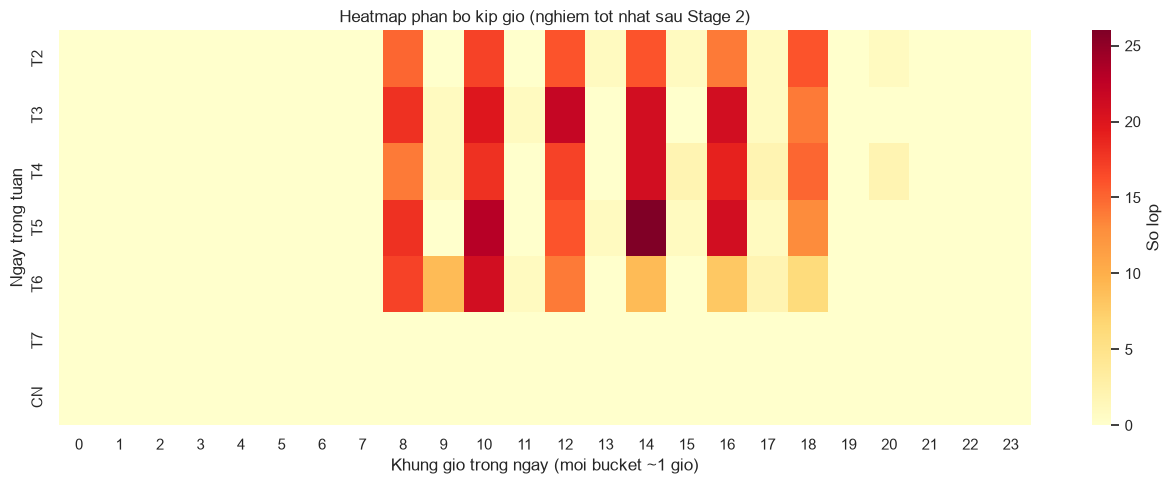

Tong so lop da xep lich (co the > so lop that su vi 1 lop co the hoc nhieu ngay/tuan): 535


In [20]:
slots_per_day = 288
n_buckets = 24  # gop moi bucket ~1 gio (12 slot) cho de doc
bucket_size = slots_per_day // n_buckets

grid = np.zeros((7, n_buckets))
for c, s in best_sol.items():
    t = class_times[c][s['t']]
    bucket = min(t['start'] // bucket_size, n_buckets - 1)
    for d in days_to_set(t['days']):
        grid[d, bucket] += 1

day_labels = ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN']

fig2, ax2 = plt.subplots(figsize=(13, 5))
sns.heatmap(grid, cmap='YlOrRd', ax=ax2, yticklabels=day_labels, cbar_kws={'label': 'So lop'})
ax2.set_xlabel('Khung gio trong ngay (moi bucket ~1 gio)')
ax2.set_ylabel('Ngay trong tuan')
ax2.set_title('Heatmap phan bo kip gio (nghiem tot nhat sau Stage 2)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'timeslot_heatmap.png', dpi=150)
plt.show()

print('Tong so lop da xep lich (co the > so lop that su vi 1 lop co the hoc nhieu ngay/tuan):', int(grid.sum()))

### Nhan xet: Heatmap phan bo kip gio

Lich hoc tap trung hoan toan trong khung Thu 2 den Thu 6 (T7, CN hoan toan trong) - phu hop voi quy luat hoc thuat thong thuong, la mot dau hieu kha thi hop ly cua nghiem.

Phat hien dang chu y: phan bo theo gio trong ngay xuat hien ro RANG KIEU BAN CO (checkered) - cac bucket gio chan (8, 10, 12, 14, 16, 18) tap trung day dac lop hoc, trong khi cac bucket le xen giua (9, 11, 13, 15, 17) gan nhu trong hoan toan. Day nhieu kha nang phan anh dac diem thiet ke thoi khoa bieu goc cua truong (cac lop bat dau dung gio chan, do dai chuan ~1.5-2 tieng), khong phai loi xu ly. Diem nong nhat la bucket 14 (~14h) ngay Thu 5, dat toi 25 lop - day la khung gio duoc uu tien nhieu nhat trong nghiem cuoi cung.

### Tra loi RQ4

RQ4 dat 2 cau hoi: (1) toc do hoi tu theo vong lap, va (2) dong gop cua cac toan tu lang gieng.

**Ve toc do hoi tu**: thuat toan hoi tu theo dang bac thang, moi buoc giam manh gan voi 1 lan kick, xen giua la cac doan giam dan deu do Great Deluge thuan tuy. Sau khi bo sung co che Kick, muc cai thien tong the tang tu 4.8% (khong Kick) len 17.4% (co Kick) tren cung mot ngan sach 20.000 vong lap - xac nhan gia thuyet rang co che Iterated (kick) la thanh phan thiet yeu, khong phai tuy chon, cho thuat toan AILS o quy mo lon.

**Ve dong gop toan tu**: dua tren phan ra Soft Penalty truoc/sau (S0 -> S_best): time_penalty giam 2362 -> 1814 (23.2%), room_penalty giam 1619 -> 1440 (11.1%), vi pham rang buoc mem giam 77 -> 67 (13%). Time_penalty cai thien manh nhat, hop ly vi 2 trong 3 toan tu (Time-Change, Time-Swap) tac dong truc tiep len thanh phan nay, trong khi chi co 1 toan tu (Room-Move) tac dong len room_penalty - goi y huong mo rong: co the can them toan tu rieng cho Room (vi du Room-Swap giua 2 lop) de can bang muc do toi uu giua cac thanh phan.

## 13. Bảng tổng hợp chỉ số hiệu năng và xuất file kết quả (Cell 9)

### Xuất bảng thời khóa biểu chi tiết (final_timetable)

In [21]:
from datetime import datetime
from pathlib import Path

DAY_NAMES = ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN']

def slot_to_hhmm(slot, slot_minutes=5):
    """Quy doi slot (don vi ITC 2019) sang gio:phut. Gia dinh chuan ITC 2019: moi slot = 5 phut."""
    total_min = slot * slot_minutes
    return f'{total_min // 60:02d}:{total_min % 60:02d}'

rows = []
for c in class_ids:
    s = best_sol[c]
    t = class_times[c][s['t']]
    room_id = class_rooms[c][s['r']]['room_id'] if s['r'] is not None else None
    days_str = ','.join(DAY_NAMES[d] for d in sorted(days_to_set(t['days'])))
    rows.append({
        'class_id': c,
        'course_id': df_classes_clean.set_index('class_id').loc[c, 'course_id'],
        'room_id': room_id,
        'days': days_str,
        'start_time': slot_to_hhmm(t['start']),
        'end_time': slot_to_hhmm(t['start'] + t['length']),
        'time_penalty': t['penalty'],
        'room_penalty': class_rooms[c][s['r']]['penalty'] if s['r'] is not None else 0,
    })
df_final = pd.DataFrame(rows)

instance_name = Path(xml_path).stem
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
out_path = OUTPUT_DIR / f'{instance_name}_timetable_{timestamp}.csv'
df_final.to_csv(out_path, index=False)

print('Da xuat thoi khoa bieu:', out_path)
print('So dong (so lop):', len(df_final))
df_final.head(10)

Da xuat thoi khoa bieu: D:\uctp_project\outputs\muni-fi-fal17_timetable_20260919_145127.csv
So dong (so lop): 535


,class_id,course_id,room_id,days,start_time,end_time,time_penalty,room_penalty
0,1,1,24,T4,10:00,11:50,0,0
1,2,2,6,T6,08:00,09:50,0,0
2,3,2,6,T6,12:00,13:50,0,0
3,4,3,14,T2,12:00,15:50,0,0
4,5,4,32,T4,10:00,11:50,0,0
5,6,4,11,T5,08:00,09:50,0,4
6,7,4,30,T5,08:00,09:50,0,4
7,8,4,30,T6,14:00,15:50,2,4
8,9,4,5,T6,14:00,15:50,2,0
9,10,4,15,T5,10:00,11:50,0,11


### Bảng tổng hợp chỉ số hiệu năng (append, không ghi đè giữa các lần chạy)

In [22]:
summary_row = {
    'instance': instance_name,
    'n_classes': len(class_ids),
    'n_rooms': len(df_rooms),
    'stage1_status': solver.StatusName(status),
    'S0_total': obj0['total'],
    'S0_time_penalty': obj0['time_penalty'],
    'S0_room_penalty': obj0['room_penalty'],
    'S0_dist_penalty': obj0['dist_penalty'],
    'Sbest_total': best_obj,
    'Sbest_time_penalty': check['time_penalty'],
    'Sbest_room_penalty': check['room_penalty'],
    'Sbest_dist_penalty': check['dist_penalty'],
    'improvement_pct': round((obj0['total'] - best_obj) / obj0['total'] * 100, 2),
    'n_kicks': history[-1][4] if history else 0,
    'run_timestamp': timestamp,
}

summary_path = OUTPUT_DIR / 'summary_all_instances.csv'
df_summary_new = pd.DataFrame([summary_row])
if summary_path.exists():
    df_summary = pd.concat([pd.read_csv(summary_path), df_summary_new], ignore_index=True)
else:
    df_summary = df_summary_new
df_summary.to_csv(summary_path, index=False)  # file tong hop: ghi de la hop ly (luon la ban moi nhat)

print('Bang tong hop hien co', len(df_summary), 'lan chay:')
df_summary

Bang tong hop hien co 2 lan chay:


,instance,n_classes,n_rooms,stage1_status,S0_total,S0_time_penalty,S0_room_penalty,S0_dist_penalty,Sbest_total,Sbest_time_penalty,Sbest_room_penalty,Sbest_dist_penalty,improvement_pct,n_kicks,run_timestamp
0,muni-fi-fal17,535,36,OPTIMAL,4751.0,2362,1619,77.0,3924.0,1814,1440,67.0,17.41,5,20260919_091653
1,muni-fi-fal17,535,36,OPTIMAL,4751.0,2362,1619,77.0,3924.0,1814,1440,67.0,17.41,5,20260919_145127


## Stage B

In [23]:
from stage_b_teacher import (
    generate_teachers, compute_stage0_metrics, get_class_candidates,
    repair_teacher_feasibility, repair_global_iterative, extract_teacher_assignment,
)

df_teachers, df_compat = generate_teachers(
    df_classes_clean, teachers_per_subpart=1, seed=RANDOM_SEED
)
df_teachers, df_compat, n_repaired_course = repair_teacher_feasibility(
    class_ids, best_sol, class_times, df_classes_clean, df_teachers, df_compat
)
class_candidates = get_class_candidates(class_ids, df_classes_clean, df_compat)
course_of = df_classes_clean.set_index('class_id')['course_id'].to_dict()

class_candidates, df_teachers, df_compat, solver_gv, teacher_bool, n_repaired_global = repair_global_iterative(
    class_ids, best_sol, class_times, class_candidates, df_teachers, df_compat, course_of
)

teacher_assignment = extract_teacher_assignment(solver_gv, teacher_bool, class_ids, class_candidates)
df_teacher_metrics, df_course_metrics = compute_stage0_metrics(df_compat, STAGE0_THRESHOLDS)

print('Tong so giao vien:', len(df_teachers))
print('So course can va (xung dot noi bo):', n_repaired_course)
print('So lan va toan cuc (xung dot cheo):', n_repaired_global)
print('Phan bo 3 nhom:', df_teacher_metrics['group'].value_counts().to_dict())
print('So lop da gan giao vien:', len(teacher_assignment), '/', len(class_ids))

RuntimeError: Khong tim duoc nghiem kha thi sau 100 lan va toan cuc.